# 05 · ¿Cuándo se pensionaría un contratista? Semanas, simulador y casos reales

**Proyecto final de Machine Learning — ¿Se pensionarán los contratistas del Estado?**

Este notebook traduce las trayectorias de SECOP II a la pregunta del proyecto: **¿a qué edad completaría cada
contratista las semanas que exige la pensión de vejez?**

**Supuestos (constantes de ley y del ejercicio)**
- Edad legal: **62 años para hombres y 57 para mujeres**.
- Semanas exigidas, **escenario principal**: **1.300 para hombres y 1.000 para mujeres**. Por la Sentencia
  **C-197 de 2023** de la Corte Constitucional, desde 2026 las mujeres necesitan 1.250 semanas y el requisito baja
  25 semanas por año hasta llegar a **1.000 en 2036**. Una mujer que empieza a cotizar hoy a los 25 cumple 57 años
  mucho después de 2036, así que para ella la regla relevante es 1.000.
- **Sensibilidad:** 1.300 semanas para todos (la regla anterior). La reportamos al lado porque cambia la conclusión
  por género.
- Una persona cotiza las semanas en las que tiene contrato: semanas por año = días con contrato / 7
  (equivale a meses × 30,44 / 7 ≈ 4,35 semanas por mes).
- Se supone que la persona **empieza a cotizar a los 25 años** y mantiene **para siempre** el ritmo que se le
  observa en 2022–2025 (semanas por año observable, la misma variable del notebook 03).
- IBC del independiente = máx(0,4 · honorario mensual, 1 SMMLV). Para el simulador se usa el SMMLV de **2025
  ($1.423.500)**, el último año completo de la ventana.

**Qué hay aquí**
1. Tiempo hasta completar las semanas, por cluster, por género y por decil de riesgo (modelo del notebook 04).
2. Un simulador `cuando_me_pensiono(...)` con un árbol de decisión pequeño que asigna el tipo de trayectoria.
3. Tres casos reales anonimizados (k ≥ 10).
4. Limitaciones: los tiempos son una **cota superior**.

In [1]:
# --- Configuración común: rutas (Colab o local), constantes de ley y estilo de gráficas ---
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from cycler import cycler
warnings.filterwarnings('ignore')

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ_DRIVE = Path('/content/drive/MyDrive/Proyecto Final SECOP')
    DATA_DIR = RAIZ_DRIVE / 'data' / 'processed'
    assert DATA_DIR.exists(), (f'No encuentro {DATA_DIR}. Sube la carpeta "Proyecto Final SECOP" (con data/processed/'
                               'secop_ps_AAAA.parquet, ver README.md) a la raíz de "Mi unidad" y vuelve a ejecutar.')
    # Las salidas quedan en "Proyecto Final SECOP/proyecto_secop/" para que las rutas relativas funcionen
    CARPETA_NB = RAIZ_DRIVE / 'proyecto_secop' / 'notebooks'
    CARPETA_NB.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA_NB)
else:
    # Local: variable de entorno SECOP_DATA o, si no existe, la estructura del README relativa al notebook
    # (proyecto_secop/ junto a data/, o proyecto_secop/ dentro de la carpeta del proyecto).
    candidatos = [os.environ.get('SECOP_DATA'), '../data/processed', '../../data/processed']
    DATA_DIR = next((Path(c) for c in candidatos if c and Path(c).exists()), None)
    if DATA_DIR is None:
        print('Aviso: no encontré data/processed; el 05 no lo necesita (solo usa data_intermedia/).')

# Salidas con rutas relativas a la carpeta notebooks/
OUT = Path('../outputs'); FIGS = OUT / 'figs'; TABLAS = OUT / 'tablas'; INTER = Path('../data_intermedia')
for _p in (FIGS, TABLAS, INTER):
    _p.mkdir(parents=True, exist_ok=True)
RESULTADOS = OUT / 'resultados.json'          # solo lectura en este notebook

# Constantes de ley (no son datos externos: salario mínimo decretado y regla del IBC del independiente)
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000,
         2024: 1_300_000, 2025: 1_423_500, 2026: 1_750_905}   # 2026: Decreto 1469 de 2025 (verificado)
FRACCION_IBC = 0.40          # el IBC del independiente es el 40% del honorario mensual
SEMANAS_PENSION = 1300       # semanas exigidas para pensión de vejez (Colpensiones)
DIAS_MES = 30.4375           # 365,25 / 12, para pasar duración en días a meses
SEMILLA = 42

# --- Estilo de gráficas para diapositivas: sobrio, letra grande, sin adornos ---
COLOR = {'azul': '#2a78d6', 'naranja': '#eb6834', 'aqua': '#1baf7a', 'amarillo': '#eda100',
         'magenta': '#e87ba4', 'verde': '#008300', 'violeta': '#6250d6', 'rojo': '#e34948',
         'gris': '#9b9a95', 'gris_claro': '#d9d8d3', 'tinta': '#0b0b0b', 'tinta2': '#52514e'}
SERIE = [COLOR[c] for c in ('azul', 'naranja', 'aqua', 'amarillo', 'magenta', 'verde', 'violeta', 'rojo')]
mpl.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.family': 'DejaVu Sans',
    'font.size': 15, 'axes.titlesize': 20, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 34, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.frameon': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9b9a95', 'axes.labelcolor': COLOR['tinta2'], 'xtick.color': COLOR['tinta2'],
    'ytick.color': COLOR['tinta2'], 'text.color': COLOR['tinta'], 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#ebeae6', 'grid.linewidth': 0.9, 'axes.axisbelow': True, 'lines.linewidth': 2.5,
    'axes.prop_cycle': cycler(color=SERIE)})

def titulo(ax, texto, sub=None):
    """Título que cuenta el hallazgo + subtítulo gris con el detalle."""
    ax.set_title(texto, loc='left')
    if sub:
        ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=13, color=COLOR['tinta2'], va='bottom')

def fuente(fig, texto='Fuente: SECOP II (datos.gov.co), contratos de prestación de servicios a personas naturales.'):
    fig.text(0.01, -0.02, texto, fontsize=10.5, color=COLOR['gris'], ha='left', va='top')

def guardar(fig, nombre):
    ruta = FIGS / f'{nombre}.png'
    fig.savefig(ruta)
    print('Figura guardada:', ruta)

def num(x, d=0):
    """Formato numérico en español: 1.234.567,8"""
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')

def pesos_millones(x, pos=None):
    return f'${num(x/1e6, 1)}M'

def pct(x, d=1):
    return f'{num(100*x, d)}%'

print('Colab:', EN_COLAB, '| DATA_DIR:', DATA_DIR, '| existe:', DATA_DIR is not None and DATA_DIR.exists())

# --- Parámetros propios de este notebook ---
RESULTADOS_05 = OUT / 'resultados_05.json'
CASOS_JSON = OUT / 'casos_reales.json'
RESUMEN_MD = OUT / 'RESUMEN_05.md'
EDAD_INICIO = 25                                   # supuesto: empieza a cotizar a los 25 años
EDAD_LEGAL = {'Hombre': 62, 'Mujer': 57}           # edad de pensión de vejez
# Semanas exigidas. Principal: C-197/2023 (mujeres: 1.250 en 2026, -25 por año, 1.000 desde 2036). Sensibilidad: 1.300 todos.
SEMANAS_EXIGIDAS = {'Hombre': 1300, 'Mujer': 1000}
SEMANAS_EXIGIDAS_SENS = {'Hombre': 1300, 'Mujer': 1300}
ANIO_SMMLV_SIM = 2025
SMMLV_SIM = SMMLV[ANIO_SMMLV_SIM]                  # $1.423.500
SEMANAS_POR_MES = 365.25 / 12 / 7                  # ≈ 4,348 semanas por mes de contrato
TASA_PENSION = 0.16                                # cotización a pensión sobre el IBC (Ley 797 de 2003)
EDAD_TOPE_GRAFICA = 100                            # para que las gráficas no se estiren hasta 140 años
ORDEN = ['Estables', 'Multientidad', 'Intermitentes', 'Ocasionales']
COL_CLUSTER = {'Estables': COLOR['azul'], 'Multientidad': COLOR['aqua'], 'Intermitentes': COLOR['violeta'],
               'Ocasionales': COLOR['naranja']}
COL_GENERO = {'Mujer': COLOR['violeta'], 'Hombre': COLOR['aqua']}
PLURAL = {'Hombre': 'Hombres', 'Mujer': 'Mujeres'}
# Semanas por año que hacen falta para completar las semanas justo a la edad legal, empezando a los 25
SEMANAS_REQ = {g: SEMANAS_EXIGIDAS[g] / (e - EDAD_INICIO) for g, e in EDAD_LEGAL.items()}
SEMANAS_REQ_SENS = {g: SEMANAS_EXIGIDAS_SENS[g] / (e - EDAD_INICIO) for g, e in EDAD_LEGAL.items()}
MESES_REQ = {g: s / SEMANAS_POR_MES for g, s in SEMANAS_REQ.items()}
MESES_REQ_SENS = {g: s / SEMANAS_POR_MES for g, s in SEMANAS_REQ_SENS.items()}

import textwrap
def titulo(ax, texto, sub=None, ancho=62):
    """Título que cuenta el hallazgo (partido en líneas para diapositiva) + subtítulo gris."""
    ax.set_title(textwrap.fill(texto, ancho), loc='left')
    if sub:
        ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=13, color=COLOR['tinta2'], va='bottom')

LINEA_LEGAL = {'Hombre': '--', 'Mujer': ':'}       # líneas de edad legal en gris (no compiten con los colores de cluster)

def guardar_tabla(df, nombre, index=True):
    ruta = TABLAS / f'{nombre}.csv'
    df.to_csv(ruta, index=index)
    print('Tabla guardada:', ruta)

def a_python(x):
    """Convierte tipos de numpy/pandas a tipos nativos para escribir JSON."""
    if isinstance(x, dict):
        return {str(k): a_python(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [a_python(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, np.bool_):
        return bool(x)
    return x

for g in EDAD_LEGAL:
    print(f'{g}: {num(SEMANAS_EXIGIDAS[g])} semanas en {EDAD_LEGAL[g] - EDAD_INICIO} años → {num(SEMANAS_REQ[g], 2)} semanas/año '
          f'= {num(MESES_REQ[g], 2)} meses de contrato cada año desde los {EDAD_INICIO}')
print(f'Sensibilidad (mujeres con 1.300): {num(SEMANAS_REQ_SENS["Mujer"], 2)} semanas/año = {num(MESES_REQ_SENS["Mujer"], 2)} meses')
assert abs(SEMANAS_REQ['Mujer'] - 1000 / 32) < 1e-9 and abs(SEMANAS_REQ['Hombre'] - 1300 / 37) < 1e-9

Colab: False | DATA_DIR: ../data/processed | existe: True
Hombre: 1.300 semanas en 37 años → 35,14 semanas/año = 8,08 meses de contrato cada año desde los 25
Mujer: 1.000 semanas en 32 años → 31,25 semanas/año = 7,19 meses de contrato cada año desde los 25
Sensibilidad (mujeres con 1.300): 40,62 semanas/año = 9,34 meses


## 0. Carga de datos (solo las columnas necesarias)
- `clusters_personas.parquet` (notebook 03): una fila por persona con su **etiqueta de cluster** (`nombre_cluster`)
  y las variables de trayectoria. La etiqueta se guardó en el notebook 03, así que no hace falta reproducir el
  K-means.
- `persona_anio_2022_2025.parquet` (notebook 01): solo para los casos reales (meses, contratos y honorario por año).
- `cobertura_2020_2025.parquet`: solo para documentar la baja cobertura de 2020–2021.

In [2]:
COLS_P = ['id_persona', 'nombre_cluster', 'primer_anio', 'anios_activos', 'anios_obs', 'semanas_por_anio_obs',
          'meses_por_anio_obs', 'meses_prom_activo', 'huecos_prom', 'honorario_mediano', 'n_entidades_prom', 'n_contratos_prom', 'genero']
P = pd.read_parquet(INTER / 'clusters_personas.parquet', columns=COLS_P).set_index('id_persona')
P['genero'] = P.genero.where(P.genero.isin(['Hombre', 'Mujer']), 'No definido').astype(str)
pa = pd.read_parquet(INTER / 'persona_anio_2022_2025.parquet',
                     columns=['id_persona', 'anio', 'meses_cubiertos', 'n_contratos', 'honorario_mensual_mediano'])
cob = pd.read_parquet(INTER / 'cobertura_2020_2025.parquet', columns=['id_persona', 'anio'])
perfil03 = pd.read_csv(TABLAS / '03_perfil_clusters.csv', index_col='nombre')
print(f'{len(P):,} personas con cluster · {len(pa):,} filas persona-año · {len(cob):,} filas de cobertura')
print(P.nombre_cluster.value_counts().loc[ORDEN])
print(P.genero.value_counts())

848,267 personas con cluster · 1,825,478 filas persona-año · 2,361,634 filas de cobertura
nombre_cluster
Estables         249680
Multientidad      55872
Intermitentes    184455
Ocasionales      358260
Name: count, dtype: int64
genero
Mujer          389273
Hombre         308293
No definido    150701
Name: count, dtype: int64


## 1. Tiempo hasta completar las semanas

Para cada persona con género definido: **años necesarios = semanas exigidas / semanas por año observable** y
**edad de llegada = 25 + años**, comparada con la edad legal de su género. Quien completa las semanas *antes* de la
edad legal se pensiona a la edad legal; quien las completa *después* se pensiona cuando las tenga (si vive para eso).

También reportamos, para todos (incluidas las personas sin género definido), los **años hasta 1.300 semanas**, que
es la medida neutra que se compara con el notebook 03.

Umbrales, empezando a los 25:
- **Hombre:** 1.300 semanas en 37 años, es decir **35,1 semanas al año** (8,1 meses de contrato cada año).
- **Mujer, escenario principal:** 1.000 semanas en 32 años, es decir **31,25 semanas al año** (7,2 meses cada año).
  Con la regla vigente, la mujer necesita un ritmo **menor** que el hombre.
- **Mujer, sensibilidad con 1.300:** 40,6 semanas al año (9,3 meses), un ritmo mayor que el del hombre.

In [3]:
s = P.semanas_por_anio_obs
P['anios_1300'] = SEMANAS_PENSION / s
P['edad_llega_1300'] = EDAD_INICIO + P.anios_1300
P['edad_legal'] = P.genero.map(EDAD_LEGAL)                          # NaN si el género no está definido
P['semanas_exigidas'] = P.genero.map(SEMANAS_EXIGIDAS)
P['anios_requisito'] = P.semanas_exigidas / s
P['edad_llega'] = EDAD_INICIO + P.anios_requisito                   # escenario principal (H 1.300, M 1.000)
P['llega_a_tiempo'] = (P.edad_llega <= P.edad_legal).where(P.edad_legal.notna())
P['llega_a_tiempo_1300'] = (P.edad_llega_1300 <= P.edad_legal).where(P.edad_legal.notna())   # sensibilidad
P['semanas_a_edad_legal'] = np.minimum(s * (P.edad_legal - EDAD_INICIO), P.semanas_exigidas)

def resumen_pension(g):
    s, a = g.semanas_por_anio_obs, g.anios_1300
    cg = g[g.edad_legal.notna()]
    return pd.Series({
        'personas': len(g), 'personas_con_genero': len(cg),
        'semanas_anio_p25': s.quantile(.25), 'semanas_anio_mediana': s.median(), 'semanas_anio_p75': s.quantile(.75),
        'anios_1300_p25': a.quantile(.25), 'anios_1300_mediana': a.median(), 'anios_1300_p75': a.quantile(.75),
        'edad_llega_1300_mediana': g.edad_llega_1300.median(),
        'anios_requisito_p25': cg.anios_requisito.quantile(.25), 'anios_requisito_mediana': cg.anios_requisito.median(),
        'anios_requisito_p75': cg.anios_requisito.quantile(.75),
        'edad_llega_mediana': cg.edad_llega.median(),
        'pct_llega_a_tiempo': cg.llega_a_tiempo.astype(float).mean(),
        'pct_llega_a_tiempo_1300_todos': cg.llega_a_tiempo_1300.astype(float).mean(),
        'pct_no_llega_ni_a_80': (cg.edad_llega > 80).mean(),
        'semanas_a_edad_legal_mediana': cg.semanas_a_edad_legal.median()})

tab_cluster = P.groupby('nombre_cluster').apply(resumen_pension).loc[ORDEN]
tab_cluster.loc['Total'] = resumen_pension(P)
tab_cluster.index.name = 'cluster'
guardar_tabla(tab_cluster, '05_pension_por_cluster')
tab_cluster.style.format({c: (lambda v: pct(v)) if c.startswith('pct') else (lambda v: num(v, 1))
                          for c in tab_cluster.columns} | {'personas': lambda v: num(v), 'personas_con_genero': lambda v: num(v)})

Tabla guardada: ../outputs/tablas/05_pension_por_cluster.csv


,personas,personas_con_genero,semanas_anio_p25,semanas_anio_mediana,semanas_anio_p75,anios_1300_p25,anios_1300_mediana,anios_1300_p75,edad_llega_1300_mediana,anios_requisito_p25,anios_requisito_mediana,anios_requisito_p75,edad_llega_mediana,pct_llega_a_tiempo,pct_llega_a_tiempo_1300_todos,pct_no_llega_ni_a_80,semanas_a_edad_legal_mediana
cluster,,,,,,,,,,,,,,,,,
Estables,249.680,180.686,"33,7","40,6","45,4","28,7","32,0","38,6","57,0","23,9","28,7","33,9","53,7","77,3%","58,0%","1,1%","1.000,0"
Multientidad,55.872,39.161,"26,3","37,8","45,2","28,8","34,4","49,5","59,4","25,9","31,4","43,8","56,4","60,3%","46,3%","16,3%","1.000,0"
Intermitentes,184.455,161.173,"18,9","25,2","33,4","38,9","51,6","68,9","76,6","33,3","43,8","60,9","68,8","27,2%","13,9%","31,7%","877,4"
Ocasionales,358.260,316.546,"6,2","11,4","17,4","74,6","114,5","210,0","139,5","63,1","101,1","185,4","126,1","2,4%","0,6%","82,1%","381,7"
Total,848.267,697.566,"11,9","23,9","37,4","34,7","54,5","109,0","79,5","31,4","49,6","100,0","74,6","30,8%","21,1%","45,8%","778,3"


### Chequeo contra los perfiles del notebook 03
La mediana de semanas por año observable debe ser la misma que reportó el notebook 03
(Estables ≈ 40,6, Multientidad ≈ 37,8, Intermitentes ≈ 25,1, Ocasionales ≈ 11,4).

In [4]:
chequeo = pd.DataFrame({'notebook_03': perfil03.loc[ORDEN, 'semanas_por_anio_mediana'],
                        'notebook_05': tab_cluster.loc[ORDEN, 'semanas_anio_mediana'],
                        'personas_03': perfil03.loc[ORDEN, 'personas'], 'personas_05': tab_cluster.loc[ORDEN, 'personas']})
chequeo['diferencia'] = chequeo.notebook_05 - chequeo.notebook_03
# resultados.json es del otro notebook: solo lo leemos para validar
res_previos = json.loads(RESULTADOS.read_text()) if RESULTADOS.exists() else {}
if '03_clustering' in res_previos:
    chequeo['resultados_json'] = [res_previos['03_clustering']['perfiles'][n]['semanas_por_anio_mediana'] for n in ORDEN]
assert (chequeo.diferencia.abs() < 0.01).all(), 'Las semanas no cuadran con el notebook 03'
assert (chequeo.personas_03 == chequeo.personas_05).all()
print('Cuadra con el notebook 03 ✔')
chequeo.round(2)

Cuadra con el notebook 03 ✔


,notebook_03,notebook_05,personas_03,personas_05,diferencia,resultados_json
Estables,40.57,40.57,249680,249680.0,0.0,40.57
Multientidad,37.75,37.75,55872,55872.0,0.0,37.75
Intermitentes,25.18,25.18,184455,184455.0,0.0,25.18
Ocasionales,11.36,11.36,358260,358260.0,0.0,11.36


### Por género: escenario principal y sensibilidad
Cambian dos cosas entre hombres y mujeres: la edad legal (62 frente a 57) y, con la regla vigente, las semanas
exigidas (1.300 frente a 1.000). Mostramos las dos reglas para que se vea cuánto depende la conclusión del supuesto.

In [5]:
Pg = P[P.genero.isin(['Hombre', 'Mujer'])]
tab_genero = Pg.groupby(['nombre_cluster', 'genero']).apply(resumen_pension)
tab_genero = tab_genero.reindex(pd.MultiIndex.from_product([ORDEN, ['Hombre', 'Mujer']]))
tot_g = Pg.groupby('genero').apply(resumen_pension)
tot_g.index = pd.MultiIndex.from_product([['Total'], tot_g.index])
tab_genero = pd.concat([tab_genero, tot_g])
tab_genero.index.names = ['cluster', 'genero']
gen_idx = tab_genero.index.get_level_values('genero')
tab_genero['edad_legal'] = gen_idx.map(EDAD_LEGAL)
tab_genero['semanas_exigidas'] = gen_idx.map(SEMANAS_EXIGIDAS)
tab_genero['brecha_mediana_vs_edad_legal'] = tab_genero.edad_llega_mediana - tab_genero.edad_legal
cols_g = ['personas', 'semanas_anio_mediana', 'semanas_exigidas', 'anios_requisito_mediana', 'edad_llega_mediana',
          'edad_legal', 'brecha_mediana_vs_edad_legal', 'pct_llega_a_tiempo', 'pct_llega_a_tiempo_1300_todos',
          'semanas_a_edad_legal_mediana']
tab_genero = tab_genero[cols_g]
guardar_tabla(tab_genero, '05_pension_cluster_genero')

# Comparación compacta de escenarios (total de personas con género definido)
tot = tab_genero.loc['Total']
escenarios = pd.DataFrame({
    'Principal (H 1.300 · M 1.000)': {'Hombres': tot.loc['Hombre', 'pct_llega_a_tiempo'], 'Mujeres': tot.loc['Mujer', 'pct_llega_a_tiempo']},
    'Sensibilidad (1.300 para todos)': {'Hombres': tot.loc['Hombre', 'pct_llega_a_tiempo_1300_todos'],
                                        'Mujeres': tot.loc['Mujer', 'pct_llega_a_tiempo_1300_todos']}}).T
escenarios['brecha_mujeres_menos_hombres_pp'] = 100 * (escenarios.Mujeres - escenarios.Hombres)
guardar_tabla(escenarios, '05_escenarios_genero')
print('% que llega a tiempo, por escenario:'); print((escenarios * [100, 100, 1]).round(1))
display(tab_genero.style.format({c: (lambda v: pct(v)) if c.startswith('pct') else (lambda v: num(v, 1)) for c in cols_g}
                                | {'personas': lambda v: num(v), 'edad_legal': '{:.0f}', 'semanas_exigidas': '{:.0f}'}))

Tabla guardada: ../outputs/tablas/05_pension_cluster_genero.csv
Tabla guardada: ../outputs/tablas/05_escenarios_genero.csv
% que llega a tiempo, por escenario:
                                 Hombres  Mujeres  \
Principal (H 1.300 · M 1.000)       26.1     34.5   
Sensibilidad (1.300 para todos)     26.1     17.1   

                                 brecha_mujeres_menos_hombres_pp  
Principal (H 1.300 · M 1.000)                                8.5  
Sensibilidad (1.300 para todos)                             -9.0  


Figura guardada: ../outputs/figs/05_edad_pension_por_cluster.png


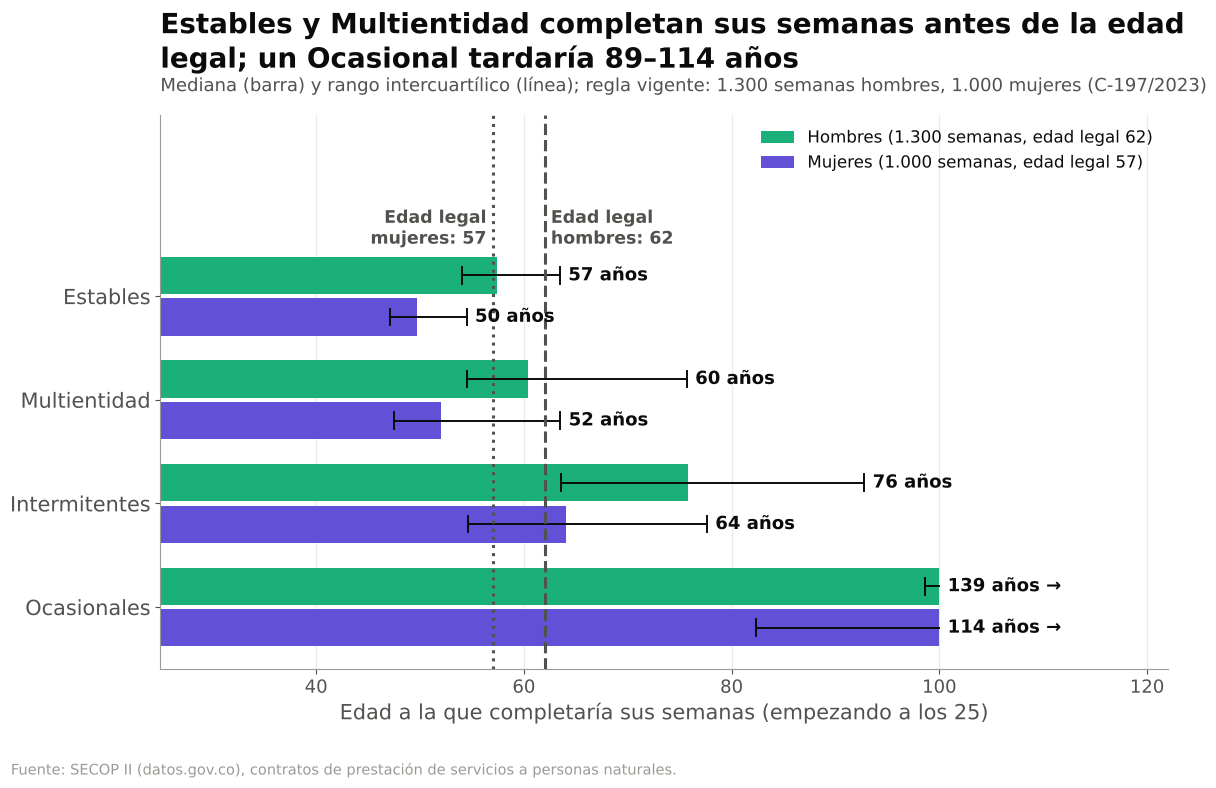

In [6]:
# Figura 1: edad a la que completaría sus semanas (mediana y rango intercuartílico), por cluster y género
fig, ax = plt.subplots(figsize=(13, 7.2))
alto = 0.36
ys = np.arange(len(ORDEN))[::-1]
for y, n in zip(ys, ORDEN):
    for k, g in enumerate(['Hombre', 'Mujer']):
        f = tab_genero.loc[(n, g)]
        yy = y + (0.2 if g == 'Hombre' else -0.2)
        med = f.edad_llega_mediana
        q25 = EDAD_INICIO + Pg.loc[(Pg.nombre_cluster == n) & (Pg.genero == g), 'anios_requisito'].quantile(.25)
        q75 = EDAD_INICIO + Pg.loc[(Pg.nombre_cluster == n) & (Pg.genero == g), 'anios_requisito'].quantile(.75)
        ax.barh(yy, min(med, EDAD_TOPE_GRAFICA) - EDAD_INICIO, left=EDAD_INICIO, color=COL_GENERO[g], height=alto,
                label=f'{PLURAL[g]} ({num(SEMANAS_EXIGIDAS[g])} semanas, edad legal {EDAD_LEGAL[g]})' if n == ORDEN[0] else None)
        if q25 <= EDAD_TOPE_GRAFICA:
            ax.plot([q25, min(q75, EDAD_TOPE_GRAFICA)], [yy, yy], color=COLOR['tinta'], lw=1.4)
            for v in (q25, q75):
                if v <= EDAD_TOPE_GRAFICA:
                    ax.plot([v, v], [yy - 0.08, yy + 0.08], color=COLOR['tinta'], lw=1.4)
        etiqueta = f'{num(med, 0)} años' if med <= EDAD_TOPE_GRAFICA else f'{num(med, 0)} años →'
        if q25 > EDAD_TOPE_GRAFICA:
            etiqueta += f' (p25 > {EDAD_TOPE_GRAFICA})'
        x_txt = max(min(med, EDAD_TOPE_GRAFICA), min(q75, EDAD_TOPE_GRAFICA))
        ax.text(x_txt + 0.8, yy, etiqueta, va='center', fontsize=13, fontweight='bold')
for g, e in EDAD_LEGAL.items():
    ax.axvline(e, color=COLOR['tinta2'], ls=LINEA_LEGAL[g], lw=2.2)
    ha, dx = ('right', -0.6) if g == 'Mujer' else ('left', 0.6)
    ax.text(e + dx, len(ORDEN) - 0.55, f'Edad legal\n{PLURAL[g].lower()}: {e}', ha=ha, va='bottom', fontsize=12.5,
            color=COLOR['tinta2'], fontweight='bold')
ax.set_yticks(ys); ax.set_yticklabels(ORDEN, fontsize=15)
ax.set_xlim(EDAD_INICIO, EDAD_TOPE_GRAFICA + 22); ax.set_ylim(-0.6, len(ORDEN) + 0.75)
ax.set_xlabel('Edad a la que completaría sus semanas (empezando a los 25)')
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.legend(loc='upper right', fontsize=12)
llegan = [n for n in ORDEN if all(tab_genero.loc[(n, g), 'edad_llega_mediana'] <= EDAD_LEGAL[g] for g in EDAD_LEGAL)]
oc = tab_genero.loc['Ocasionales']
titulo(ax, f'{" y ".join(llegan)} completan sus semanas antes de la edad legal; un Ocasional tardaría '
           f'{num(oc.loc["Mujer", "anios_requisito_mediana"], 0)}–{num(oc.loc["Hombre", "anios_requisito_mediana"], 0)} años',
       'Mediana (barra) y rango intercuartílico (línea); regla vigente: 1.300 semanas hombres, 1.000 mujeres (C-197/2023)')
fuente(fig); guardar(fig, '05_edad_pension_por_cluster'); plt.show()

Figura guardada: ../outputs/figs/05_semanas_requeridas.png


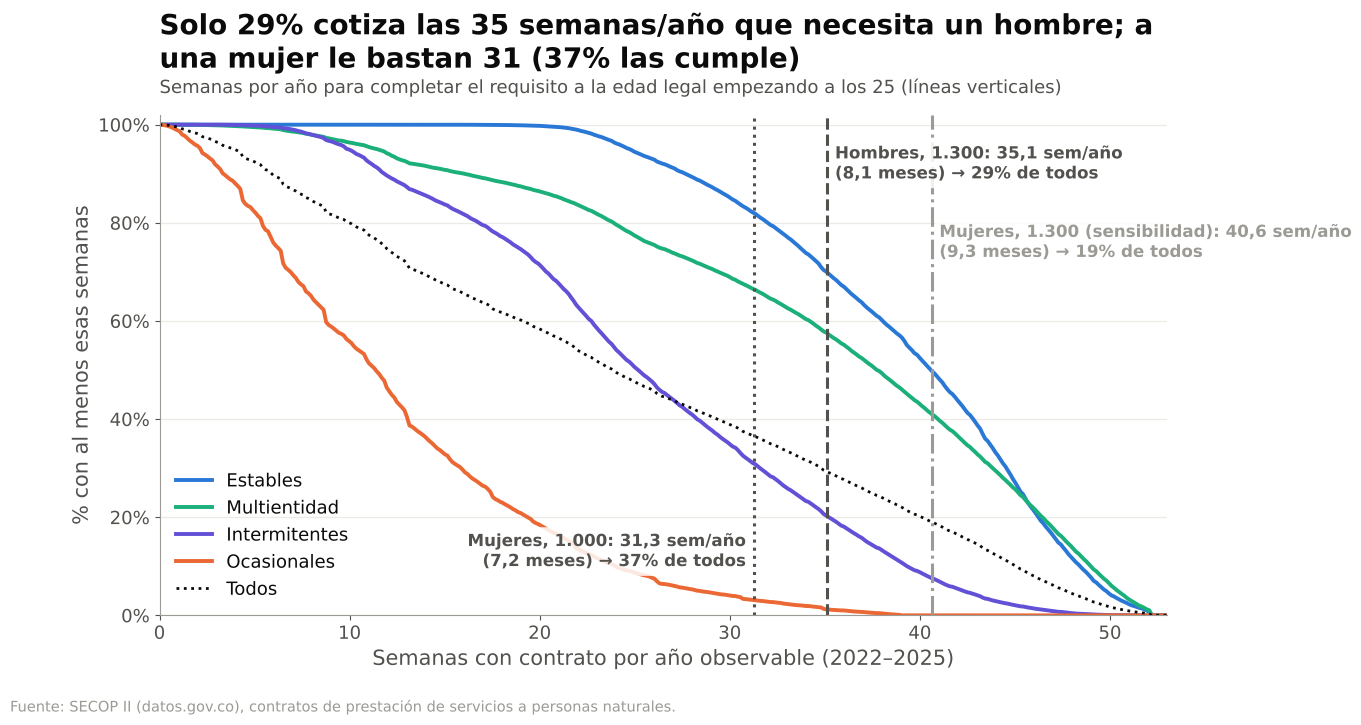

In [7]:
# Figura 2: % de personas que cotiza al menos X semanas por año, con los umbrales de hombres y mujeres
fig, ax = plt.subplots(figsize=(13, 6.5))
xs = np.linspace(0, 53, 400)
for n in ORDEN:
    sv = np.sort(P.loc[P.nombre_cluster == n, 'semanas_por_anio_obs'].values)
    ax.plot(xs, 1 - np.searchsorted(sv, xs, side='left') / len(sv), color=COL_CLUSTER[n], lw=2.8, label=n)
s_all = np.sort(P.semanas_por_anio_obs.values)
ax.plot(xs, 1 - np.searchsorted(s_all, xs, side='left') / len(s_all), color=COLOR['tinta'], lw=2, ls=':', label='Todos')
sup = {g: (P.semanas_por_anio_obs >= SEMANAS_REQ[g]).mean() for g in EDAD_LEGAL}
sup_sens_m = (P.semanas_por_anio_obs >= SEMANAS_REQ_SENS['Mujer']).mean()
umbrales = [('Hombre', SEMANAS_REQ['Hombre'], MESES_REQ['Hombre'], sup['Hombre'], '1.300', 'left', 0.4, 0.92, COLOR['tinta2'], '--'),
            ('Mujer', SEMANAS_REQ['Mujer'], MESES_REQ['Mujer'], sup['Mujer'], '1.000', 'right', -0.4, 0.13, COLOR['tinta2'], ':'),
            ('Mujer', SEMANAS_REQ_SENS['Mujer'], MESES_REQ_SENS['Mujer'], sup_sens_m, '1.300 (sensibilidad)', 'left', 0.4, 0.76,
             COLOR['gris'], '-.')]
for g, x, m, sp, sem, ha, dx, yt, col, ls in umbrales:
    ax.axvline(x, color=col, ls=ls, lw=2.2)
    ax.text(x + dx, yt, f'{PLURAL[g]}, {sem}: {num(np.round(x + 1e-9, 1), 1)} sem/año\n({num(m, 1)} meses) → {pct(sp, 0)} de todos',
            color=col, fontsize=12, fontweight='bold', va='center', ha=ha, zorder=5,
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85))
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1.02); ax.set_xlim(0, 53)
ax.set_xlabel('Semanas con contrato por año observable (2022–2025)'); ax.set_ylabel('% con al menos esas semanas')
ax.legend(loc='lower left', ncol=1)
titulo(ax, f'Solo {pct(sup["Hombre"], 0)} cotiza las {num(SEMANAS_REQ["Hombre"], 0)} semanas/año que necesita un hombre; '
           f'a una mujer le bastan {num(SEMANAS_REQ["Mujer"], 0)} ({pct(sup["Mujer"], 0)} las cumple)',
       'Semanas por año para completar el requisito a la edad legal empezando a los 25 (líneas verticales)')
fuente(fig); guardar(fig, '05_semanas_requeridas'); plt.show()

Figura guardada: ../outputs/figs/05_a_tiempo_por_genero.png


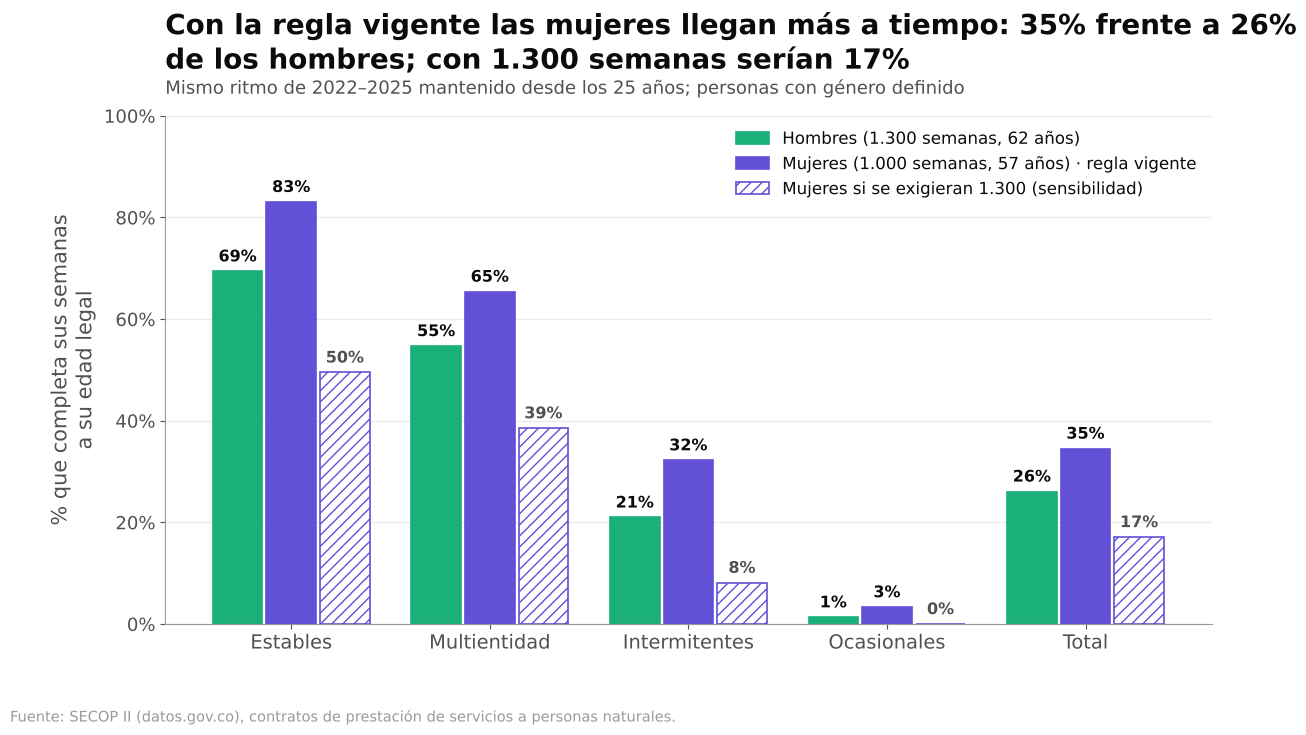

In [8]:
# Figura 3: % que llega a tiempo (a su edad legal) por cluster y género, con la sensibilidad de 1.300 para mujeres
fig, ax = plt.subplots(figsize=(13.5, 6.6))
w = 0.27
grupos = ORDEN + ['Total']
series = [('Hombre', 'pct_llega_a_tiempo', f'Hombres (1.300 semanas, 62 años)', COL_GENERO['Hombre'], None),
          ('Mujer', 'pct_llega_a_tiempo', f'Mujeres (1.000 semanas, 57 años) · regla vigente', COL_GENERO['Mujer'], None),
          ('Mujer', 'pct_llega_a_tiempo_1300_todos', 'Mujeres si se exigieran 1.300 (sensibilidad)', 'white', '///')]
for i, (g, col_v, lab, color, hatch) in enumerate(series):
    xs = np.arange(len(grupos)) + (i - 1) * w
    vals = [tab_genero.loc[(n, g), col_v] for n in grupos]
    ax.bar(xs, vals, width=w - 0.02, color=color, label=lab, hatch=hatch,
           edgecolor=COL_GENERO['Mujer'] if hatch else color, linewidth=1.2)
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.012, pct(v, 0), ha='center', va='bottom', fontsize=11.5, fontweight='bold',
                color=COLOR['tinta2'] if hatch else COLOR['tinta'])
ax.set_xticks(np.arange(len(grupos))); ax.set_xticklabels(grupos, fontsize=14)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1.0)
ax.set_ylabel('% que completa sus semanas\na su edad legal'); ax.legend(loc='upper right', fontsize=12)
th, tm = tot.loc['Hombre', 'pct_llega_a_tiempo'], tot.loc['Mujer', 'pct_llega_a_tiempo']
tm_s = tot.loc['Mujer', 'pct_llega_a_tiempo_1300_todos']
titulo(ax, f'Con la regla vigente las mujeres llegan {"más" if tm > th else "menos"} a tiempo: {pct(tm, 0)} frente a '
           f'{pct(th, 0)} de los hombres; con 1.300 semanas serían {pct(tm_s, 0)}',
       'Mismo ritmo de 2022–2025 mantenido desde los 25 años; personas con género definido', ancho=70)
fuente(fig); guardar(fig, '05_a_tiempo_por_genero'); plt.show()

**Lectura por género.** La conclusión depende de la regla de semanas.
- **Con la regla vigente** (1.000 semanas para mujeres, C-197 de 2023), una mujer necesita 31,25 semanas al año y un
  hombre 35,1, así que **las mujeres llegan más a tiempo que los hombres** en todos los tipos de trayectoria.
- **Con 1.300 semanas para todos**, la mujer tendría que juntar las mismas semanas con 5 años menos, así que
  llegaría menos a tiempo. Ese era el resultado de la versión anterior de este notebook. Ya no es la regla aplicable
  a quien empieza a cotizar hoy.

### Por decil de riesgo (modelo supervisado del notebook 04)
El notebook 04 ordena a las personas activas en 2024 por su probabilidad de continuidad en 2025 y las agrupa
en deciles (archivo `riesgo_2024_2025.parquet`, con `id_persona`, `prob` y `decil`). Convención: **D1 = mayor
riesgo** (menor probabilidad de continuidad). Aquí cruzamos cada decil con su ritmo de cotización (semanas por año
observable 2022–2025, la misma medida de los clusters).
**Ojo:** esa medida incluye 2025, el año que el modelo predice; aquí no se evalúa el modelo, solo se describe qué
implica cada decil para la pensión.

In [9]:
RUTA_RIESGO = INTER / 'riesgo_2024_2025.parquet'
RIESGO_OK = RUTA_RIESGO.exists()
tab_decil, info_decil = None, {}
if RIESGO_OK:
    r = pd.read_parquet(RUTA_RIESGO, columns=['id_persona', 'prob', 'decil']).set_index('id_persona')
    medias = r.groupby('decil').prob.mean()
    # Convención acordada con el 04: decil 1 = mayor riesgo (menor probabilidad de continuidad). Se verifica.
    D1_ES_MAYOR_RIESGO = bool(medias.is_monotonic_increasing)
    assert D1_ES_MAYOR_RIESGO, 'Se esperaba D1 = mayor riesgo (probabilidad creciente por decil): revisar el archivo del 04'
    R = r.join(P, how='inner')
    info_decil = {'personas_archivo': int(len(r)), 'personas_con_cluster': int(len(R)),
                  'd1_es_mayor_riesgo': D1_ES_MAYOR_RIESGO}
    print(info_decil)
    tab_decil = R.groupby('decil').apply(resumen_pension)
    tab_decil.insert(1, 'prob_continuidad_media', R.groupby('decil').prob.mean())
    comp = pd.crosstab(R.decil, R.nombre_cluster, normalize='index')[ORDEN].add_prefix('pct_')
    tab_decil = tab_decil.join(comp)
    guardar_tabla(tab_decil, '05_pension_por_decil_riesgo')
    display(tab_decil[['personas', 'prob_continuidad_media', 'semanas_anio_mediana', 'anios_1300_mediana',
                       'edad_llega_mediana', 'pct_llega_a_tiempo', 'pct_llega_a_tiempo_1300_todos'] + list(comp.columns)].round(3))
else:
    print('PENDIENTE: todavía no existe', RUTA_RIESGO, '— el notebook 04 aún no lo ha escrito. '
          'Vuelve a ejecutar esta sección cuando exista.')

{'personas_archivo': 471549, 'personas_con_cluster': 471549, 'd1_es_mayor_riesgo': True}


Tabla guardada: ../outputs/tablas/05_pension_por_decil_riesgo.csv


,personas,prob_continuidad_media,semanas_anio_mediana,anios_1300_mediana,edad_llega_mediana,pct_llega_a_tiempo,pct_llega_a_tiempo_1300_todos,pct_Estables,pct_Multientidad,pct_Intermitentes,pct_Ocasionales
decil,,,,,,,,,,,
1,47155.0,0.057,15.893,81.798,101.087,0.054,0.014,0.117,0.016,0.229,0.638
2,47155.0,0.111,25.464,51.052,71.018,0.214,0.080,0.220,0.040,0.357,0.383
3,47155.0,0.173,28.929,44.938,65.307,0.341,0.165,0.263,0.050,0.395,0.292
4,47155.0,0.245,30.750,42.276,63.147,0.412,0.245,0.312,0.070,0.333,0.285
5,47155.0,0.333,33.000,39.394,60.034,0.488,0.327,0.397,0.095,0.266,0.242
6,47154.0,0.424,33.786,38.478,59.340,0.507,0.345,0.451,0.094,0.266,0.190
7,47155.0,0.495,34.679,37.487,58.766,0.517,0.367,0.528,0.098,0.134,0.240
8,47155.0,0.559,38.476,33.787,55.308,0.624,0.462,0.652,0.118,0.087,0.143
9,47155.0,0.632,42.464,30.614,53.130,0.746,0.583,0.766,0.129,0.039,0.066


Figura guardada: ../outputs/figs/05_pension_por_decil.png


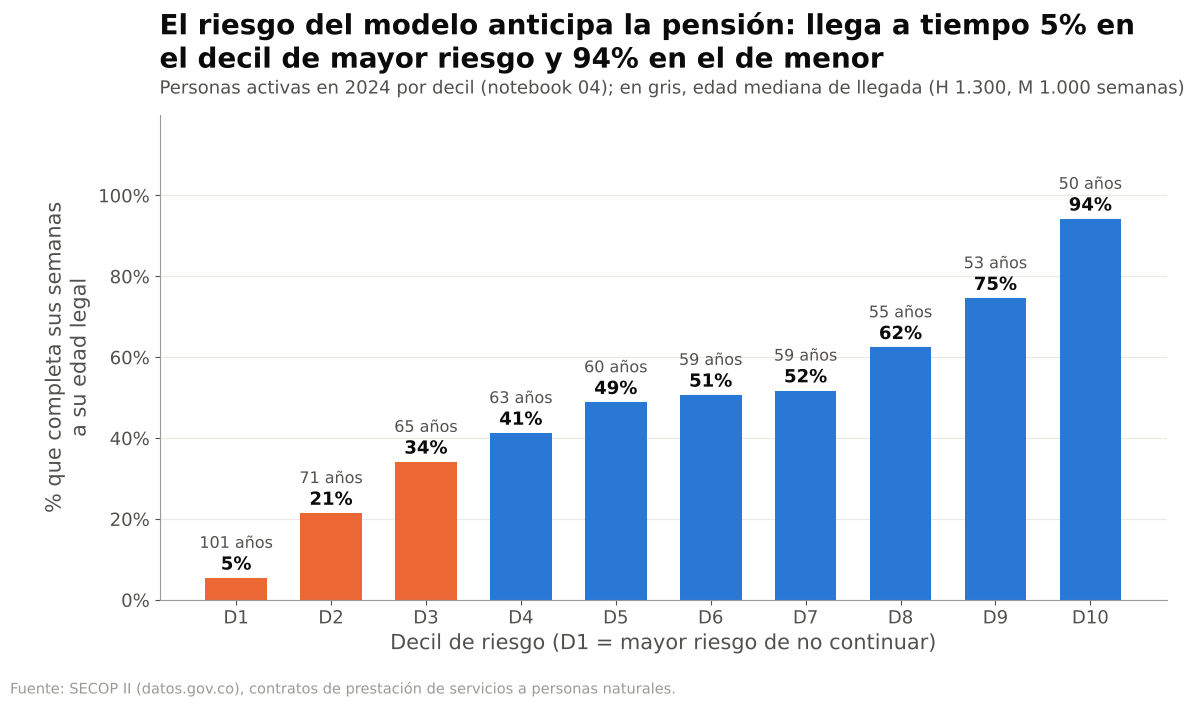

In [10]:
if RIESGO_OK:
    fig, ax = plt.subplots(figsize=(13, 6.3))
    dd = tab_decil.index.values
    riesgo_alto = dd[:3]
    vals = tab_decil.pct_llega_a_tiempo.values
    ax.bar(dd, vals, width=0.65, color=[COLOR['naranja'] if d in riesgo_alto else COLOR['azul'] for d in dd])
    for d, v, e in zip(dd, vals, tab_decil.edad_llega_mediana.values):
        ax.text(d, v + 0.01, pct(v, 0), ha='center', va='bottom', fontsize=13, fontweight='bold')
        ax.text(d, v + 0.065, f'{num(min(e, 999), 0)} años', ha='center', va='bottom', fontsize=11.5,
                color=COLOR['tinta2'])
    ax.set_xticks(dd); ax.set_xticklabels([f'D{d}' for d in dd])
    ax.set_xlabel('Decil de riesgo (D1 = mayor riesgo de no continuar)')
    ax.set_ylabel('% que completa sus semanas\na su edad legal')
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, max(vals) * 1.22 + 0.05)
    d_alto, d_bajo = dd[0], dd[-1]
    titulo(ax, f'El riesgo del modelo anticipa la pensión: llega a tiempo {pct(tab_decil.loc[d_alto, "pct_llega_a_tiempo"], 0)} '
               f'en el decil de mayor riesgo y {pct(tab_decil.loc[d_bajo, "pct_llega_a_tiempo"], 0)} en el de menor',
           'Personas activas en 2024 por decil (notebook 04); en gris, edad mediana de llegada (H 1.300, M 1.000 semanas)')
    fuente(fig); guardar(fig, '05_pension_por_decil'); plt.show()
else:
    print('PENDIENTE: figura por decil de riesgo (falta riesgo_2024_2025.parquet)')

## 2. Simulador: `cuando_me_pensiono(...)`

### 2.1 Árbol de decisión para asignar el tipo de trayectoria
Ajustamos un árbol pequeño (profundidad ≤ 3) que predice el cluster del notebook 03 usando **solo variables que una
persona puede escribir**: meses de contrato al año (promedio, contando en cero los años sin contrato), honorario
mensual y número de entidades con las que trabaja al año. Partición 80/20 estratificada.

Un árbol sin pesos **nunca predice "Intermitentes"**: ese grupo queda entre Ocasionales y Estables y se parte
entre ambos. Para que el simulador pueda devolver los cuatro tipos usamos `class_weight='balanced'`, que cambia un
poco de exactitud global por exactitud balanceada. Reportamos las dos versiones.

In [11]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

VARS_ARBOL = {'meses_por_anio_obs': 'meses_contrato_por_anio', 'honorario_mediano': 'honorario_mensual',
              'n_entidades_prom': 'n_entidades'}
XA = P[list(VARS_ARBOL)].rename(columns=VARS_ARBOL)
yA = P.nombre_cluster.astype(object).to_numpy()
XA_tr, XA_te, yA_tr, yA_te = train_test_split(XA, yA, test_size=0.2, stratify=yA, random_state=SEMILLA)

def ajustar_arbol(X_tr, y_tr, X_te, y_te, pesos):
    m = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, class_weight=pesos, random_state=SEMILLA).fit(X_tr, y_tr)
    p = m.predict(X_te)
    return m, {'exactitud': accuracy_score(y_te, p), 'exactitud_balanceada': balanced_accuracy_score(y_te, p),
               'clusters_que_predice': sorted(set(p))}

arbol_sin_pesos, met_sin = ajustar_arbol(XA_tr, yA_tr, XA_te, yA_te, None)
arbol, met_arbol = ajustar_arbol(XA_tr, yA_tr, XA_te, yA_te, 'balanced')
# Sensibilidad (no se usa en el simulador): ¿cuánto ayuda saber cuántos contratos firma al año?
XB = XA.assign(contratos_por_anio=P.n_contratos_prom.values)
XB_tr, XB_te = XB.loc[XA_tr.index], XB.loc[XA_te.index]
_, met_con_contratos = ajustar_arbol(XB_tr, yA_tr, XB_te, yA_te, 'balanced')
comp_arboles = pd.DataFrame({'Sin pesos (3 variables)': met_sin, 'Balanceado (3 variables) ← simulador': met_arbol,
                             'Balanceado + contratos/año (sensibilidad)': met_con_contratos}).T
guardar_tabla(comp_arboles, '05_arbol_comparacion')
comp_arboles

Tabla guardada: ../outputs/tablas/05_arbol_comparacion.csv


,exactitud,exactitud_balanceada,clusters_que_predice
Sin pesos (3 variables),0.711772,0.696459,"[Estables, Multientidad, Ocasionales]"
Balanceado (3 variables) ← simulador,0.698368,0.724231,"[Estables, Intermitentes, Multientidad, Ocasio..."
Balanceado + contratos/año (sensibilidad),0.800005,0.824891,"[Estables, Intermitentes, Multientidad, Ocasio..."


In [12]:
pred_te = arbol.predict(XA_te)
cm = pd.DataFrame(confusion_matrix(yA_te, pred_te, labels=ORDEN, normalize='true'), index=ORDEN, columns=ORDEN)
cm.index.name = 'real \\ predicho'
guardar_tabla(cm, '05_arbol_matriz_confusion')
REGLAS_TEXTO = export_text(arbol, feature_names=list(XA.columns), decimals=2, show_weights=False)

def reglas_simplificadas(m, nombres):
    """Une las ramas que terminan en el mismo cluster y devuelve reglas legibles."""
    t, clases = m.tree_, m.classes_
    def clases_hoja(n):
        if t.children_left[n] == -1:
            return {clases[t.value[n][0].argmax()]}
        return clases_hoja(t.children_left[n]) | clases_hoja(t.children_right[n])
    ETQ = {'meses_contrato_por_anio': 'meses de contrato al año', 'honorario_mensual': 'honorario mensual',
           'n_entidades': 'entidades al año'}
    def fmt(f, th):
        return f'${num(th / 1e6, 2)}M' if f == 'honorario_mensual' else num(th, 2)
    def texto(conds):
        lim = {}
        for f, op, th in conds:
            lo, hi = lim.get(f, (None, None))
            lim[f] = (max(lo, th) if op == '>' and lo is not None else (th if op == '>' else lo),
                      min(hi, th) if op == '<=' and hi is not None else (th if op == '<=' else hi))
        out_c = []
        for f, (lo, hi) in lim.items():
            if lo is not None and hi is not None:
                out_c.append(f'{fmt(f, lo)} < {ETQ[f]} ≤ {fmt(f, hi)}')
            elif lo is not None:
                out_c.append(f'{ETQ[f]} > {fmt(f, lo)}')
            else:
                out_c.append(f'{ETQ[f]} ≤ {fmt(f, hi)}')
        return out_c or ['(siempre)']
    out = []
    def rec(n, conds):
        cs = clases_hoja(n)
        if len(cs) == 1:
            out.append({'condiciones': texto(conds), 'cluster': cs.pop(), 'personas_entrenamiento': int(t.n_node_samples[n])})
            return
        f, th = nombres[t.feature[n]], t.threshold[n]
        rec(t.children_left[n], conds + [(f, '<=', th)])
        rec(t.children_right[n], conds + [(f, '>', th)])
    rec(0, [])
    return out

REGLAS = reglas_simplificadas(arbol, list(XA.columns))
(TABLAS / '05_arbol_reglas.txt').write_text(
    'Árbol de decisión (profundidad 3, class_weight=balanced) para asignar el tipo de trayectoria\n'
    f'Exactitud en prueba: {met_arbol["exactitud"]:.3f} · exactitud balanceada: {met_arbol["exactitud_balanceada"]:.3f}\n\n'
    + REGLAS_TEXTO + '\nReglas simplificadas:\n'
    + '\n'.join(f'SI {" Y ".join(r["condiciones"])} → {r["cluster"]}' for r in REGLAS) + '\n', encoding='utf-8')
print(REGLAS_TEXTO)
print('Reglas simplificadas:')
for r in REGLAS:
    print(f'  SI {" Y ".join(r["condiciones"])}  →  {r["cluster"]}  ({num(r["personas_entrenamiento"])} personas)')
IMPORTANCIA_ARBOL = dict(zip(XA.columns, arbol.feature_importances_))
print('\nImportancia de cada variable en el árbol:', {k: round(float(v), 3) for k, v in IMPORTANCIA_ARBOL.items()})
print(f'\nExactitud: {pct(met_arbol["exactitud"])} · exactitud balanceada: {pct(met_arbol["exactitud_balanceada"])}')
cm.round(2)

Tabla guardada: ../outputs/tablas/05_arbol_matriz_confusion.csv
|--- n_entidades <= 1.42
|   |--- meses_contrato_por_anio <= 5.04
|   |   |--- meses_contrato_por_anio <= 2.05
|   |   |   |--- class: Ocasionales
|   |   |--- meses_contrato_por_anio >  2.05
|   |   |   |--- class: Ocasionales
|   |--- meses_contrato_por_anio >  5.04
|   |   |--- meses_contrato_por_anio <= 8.98
|   |   |   |--- class: Intermitentes
|   |   |--- meses_contrato_por_anio >  8.98
|   |   |   |--- class: Estables
|--- n_entidades >  1.42
|   |--- n_entidades <= 1.58
|   |   |--- meses_contrato_por_anio <= 5.00
|   |   |   |--- class: Multientidad
|   |   |--- meses_contrato_por_anio >  5.00
|   |   |   |--- class: Multientidad
|   |--- n_entidades >  1.58
|   |   |--- meses_contrato_por_anio <= 1.34
|   |   |   |--- class: Multientidad
|   |   |--- meses_contrato_por_anio >  1.34
|   |   |   |--- class: Multientidad

Reglas simplificadas:
  SI entidades al año ≤ 1,42 Y meses de contrato al año ≤ 5,04  →  Ocasi

,Estables,Multientidad,Intermitentes,Ocasionales
real \ predicho,,,,
Estables,0.55,0.03,0.41,0.01
Multientidad,0.01,0.98,0.01,0.00
Intermitentes,0.11,0.03,0.51,0.35
Ocasionales,0.00,0.01,0.13,0.85


**Cómo leer el árbol.** El árbol no usa el honorario (importancia 0): el tipo de trayectoria lo definen **cuántos meses al
año hay contrato** y **con cuántas entidades** se trabaja. Los Multientidad se reconocen muy bien por el número de
entidades. La frontera difícil es Estables ↔ Intermitentes ↔ Ocasionales, porque es un continuo (el notebook 03 ya
mostraba siluetas bajas). Si además se conoce el número de contratos al año, la exactitud sube (ver la fila de
sensibilidad), porque los Intermitentes firman varios contratos cortos. Lo dejamos fuera del simulador para
respetar las tres variables pedidas.

### 2.2 La función

In [13]:
def cuando_me_pensiono(meses_por_anio, honorario_mensual, semanas_actuales=0, edad_actual=25, genero="Hombre",
                       n_entidades=1, semanas_requeridas=None):
    """Proyecta cuándo completaría una persona las semanas de pensión si mantiene su ritmo de contratos.

    meses_por_anio: meses con contrato en un año típico (0–12), contando los años sin contrato.
    honorario_mensual: honorario mensual del contrato en pesos.
    semanas_actuales: semanas que ya tiene cotizadas.
    edad_actual: edad hoy. genero: "Hombre" o "Mujer" (edad legal 62 o 57; semanas exigidas 1.300 o 1.000).
    n_entidades: entidades con las que trabaja al año (opcional, solo para asignar el tipo de trayectoria).
    semanas_requeridas: para sensibilidad (p. ej. 1300 para una mujer con la regla anterior). Por defecto, la regla vigente.
    """
    if not 0 <= meses_por_anio <= 12:
        raise ValueError('meses_por_anio debe estar entre 0 y 12')
    if honorario_mensual <= 0:
        raise ValueError('honorario_mensual debe ser positivo')
    g = str(genero).strip().capitalize()
    if g not in EDAD_LEGAL:
        raise ValueError('genero debe ser "Hombre" o "Mujer"')
    edad_legal = EDAD_LEGAL[g]
    exigidas = SEMANAS_EXIGIDAS[g] if semanas_requeridas is None else semanas_requeridas
    semanas_anio = meses_por_anio * SEMANAS_POR_MES
    ibc = max(FRACCION_IBC * honorario_mensual, SMMLV_SIM)
    cotiza_sobre_minimo = FRACCION_IBC * honorario_mensual <= SMMLV_SIM
    faltan = max(exigidas - semanas_actuales, 0)
    anios_faltan = faltan / semanas_anio if semanas_anio > 0 else float('inf')
    edad_llega = edad_actual + anios_faltan
    anios_hasta_legal = max(edad_legal - edad_actual, 0)
    semanas_a_edad_legal = min(semanas_actuales + semanas_anio * anios_hasta_legal, exigidas)
    meses_necesarios = faltan / anios_hasta_legal / SEMANAS_POR_MES if anios_hasta_legal > 0 else float('inf')
    x = pd.DataFrame([[meses_por_anio, honorario_mensual, n_entidades]], columns=list(XA.columns))
    proba = dict(zip(arbol.classes_, arbol.predict_proba(x)[0]))
    return {
        'semanas_requeridas': exigidas,
        'semanas_por_anio': round(semanas_anio, 1),
        'ibc': round(ibc),
        'aporte_pension_mensual': round(TASA_PENSION * ibc),
        'cotiza_sobre_minimo': bool(cotiza_sobre_minimo),
        'semanas_que_faltan': round(faltan, 1),
        'anios_que_faltan': round(anios_faltan, 1),
        'edad_a_la_que_llega': round(edad_llega, 1),
        'edad_legal': edad_legal,
        'llega_antes_de_edad_legal': bool(edad_llega <= edad_legal),
        'edad_probable_de_pension': round(max(edad_llega, edad_legal), 1),
        'semanas_a_la_edad_legal': round(semanas_a_edad_legal, 1),
        'meses_por_anio_necesarios_para_llegar_a_tiempo': round(meses_necesarios, 1),
        'cluster_mas_probable': arbol.predict(x)[0],
        'probabilidad_cluster': {k: round(float(v), 3) for k, v in sorted(proba.items(), key=lambda kv: -kv[1])},
    }

def contar(r, nombre=''):
    """Imprime el resultado del simulador en español sencillo."""
    req = num(r['semanas_requeridas'])
    llega = (f'completa sus {req} semanas a los {num(r["edad_a_la_que_llega"], 1)} años'
             if np.isfinite(r['edad_a_la_que_llega']) else f'nunca completa sus {req} semanas')
    a_tiempo = 'antes de' if r['llega_antes_de_edad_legal'] else 'después de'
    print(f'— {nombre}')
    print(f'  {num(r["semanas_por_anio"], 1)} semanas/año · IBC ${num(r["ibc"])} '
          f'({"cotiza sobre 1 SMMLV" if r["cotiza_sobre_minimo"] else "cotiza sobre el 40% del honorario"}) · '
          f'aporte a pensión ≈ ${num(r["aporte_pension_mensual"])}/mes')
    print(f'  Le faltan {num(r["semanas_que_faltan"], 0)} semanas = {num(r["anios_que_faltan"], 1)} años: {llega}, '
          f'{a_tiempo} su edad legal ({r["edad_legal"]}).')
    print(f'  A la edad legal tendría {num(r["semanas_a_la_edad_legal"], 0)} semanas. Para llegar a tiempo necesitaría '
          f'{num(r["meses_por_anio_necesarios_para_llegar_a_tiempo"], 1)} meses de contrato al año.')
    print(f'  Tipo de trayectoria más probable: {r["cluster_mas_probable"]} {r["probabilidad_cluster"]}\n')

# Verificaciones rápidas de la regla por género
assert cuando_me_pensiono(12, 3e6, genero='Mujer')['semanas_requeridas'] == 1000
assert cuando_me_pensiono(12, 3e6, genero='Hombre')['semanas_requeridas'] == 1300
assert cuando_me_pensiono(12, 3e6, genero='Mujer', semanas_requeridas=1300)['semanas_requeridas'] == 1300

### 2.3 Tres ejemplos concretos
Para las mujeres se muestra también la edad de llegada si se le exigieran 1.300 semanas (sensibilidad).

In [14]:
EJEMPLOS = [
    ('Profesional con contrato casi todo el año', dict(meses_por_anio=11, honorario_mensual=5_000_000,
                                                      semanas_actuales=150, edad_actual=28, genero='Mujer')),
    ('Apoyo a la gestión con huecos entre contratos', dict(meses_por_anio=6.5, honorario_mensual=2_200_000,
                                                          semanas_actuales=0, edad_actual=25, genero='Hombre')),
    ('Contratista ocasional (un contrato corto al año)', dict(meses_por_anio=3, honorario_mensual=3_000_000,
                                                             semanas_actuales=100, edad_actual=30, genero='Mujer')),
]
filas_ej = []
for nombre, kw in EJEMPLOS:
    r = cuando_me_pensiono(**kw)
    contar(r, nombre)
    r1300 = cuando_me_pensiono(**kw, semanas_requeridas=1300)
    filas_ej.append({'ejemplo': nombre, **kw, **{k: v for k, v in r.items() if k != 'probabilidad_cluster'},
                     'edad_a_la_que_llega_si_1300': r1300['edad_a_la_que_llega'],
                     'llega_a_tiempo_si_1300': r1300['llega_antes_de_edad_legal']})
tab_ej = pd.DataFrame(filas_ej)
guardar_tabla(tab_ej, '05_simulador_ejemplos', index=False)
tab_ej[['ejemplo', 'genero', 'semanas_requeridas', 'semanas_por_anio', 'anios_que_faltan', 'edad_a_la_que_llega',
        'edad_legal', 'edad_a_la_que_llega_si_1300', 'cluster_mas_probable']]

— Profesional con contrato casi todo el año
  47,8 semanas/año · IBC $2.000.000 (cotiza sobre el 40% del honorario) · aporte a pensión ≈ $320.000/mes
  Le faltan 850 semanas = 17,8 años: completa sus 1.000 semanas a los 45,8 años, antes de su edad legal (57).
  A la edad legal tendría 1.000 semanas. Para llegar a tiempo necesitaría 6,7 meses de contrato al año.
  Tipo de trayectoria más probable: Estables {'Estables': 0.826, 'Intermitentes': 0.158, 'Multientidad': 0.016, 'Ocasionales': 0.0}

— Apoyo a la gestión con huecos entre contratos
  28,3 semanas/año · IBC $1.423.500 (cotiza sobre 1 SMMLV) · aporte a pensión ≈ $227.760/mes
  Le faltan 1.300 semanas = 46,0 años: completa sus 1.300 semanas a los 71,0 años, después de su edad legal (62).
  A la edad legal tendría 1.046 semanas. Para llegar a tiempo necesitaría 8,1 meses de contrato al año.
  Tipo de trayectoria más probable: Intermitentes {'Intermitentes': 0.477, 'Estables': 0.388, 'Ocasionales': 0.126, 'Multientidad': 0.008}

— Co

,ejemplo,genero,semanas_requeridas,semanas_por_anio,anios_que_faltan,edad_a_la_que_llega,edad_legal,edad_a_la_que_llega_si_1300,cluster_mas_probable
0,Profesional con contrato casi todo el año,Mujer,1000,47.8,17.8,45.8,57,52.0,Estables
1,Apoyo a la gestión con huecos entre contratos,Hombre,1300,28.3,46.0,71.0,62,71.0,Intermitentes
2,Contratista ocasional (un contrato corto al año),Mujer,1000,13.0,69.0,99.0,57,122.0,Ocasionales


Figura guardada: ../outputs/figs/05_simulador_curva.png


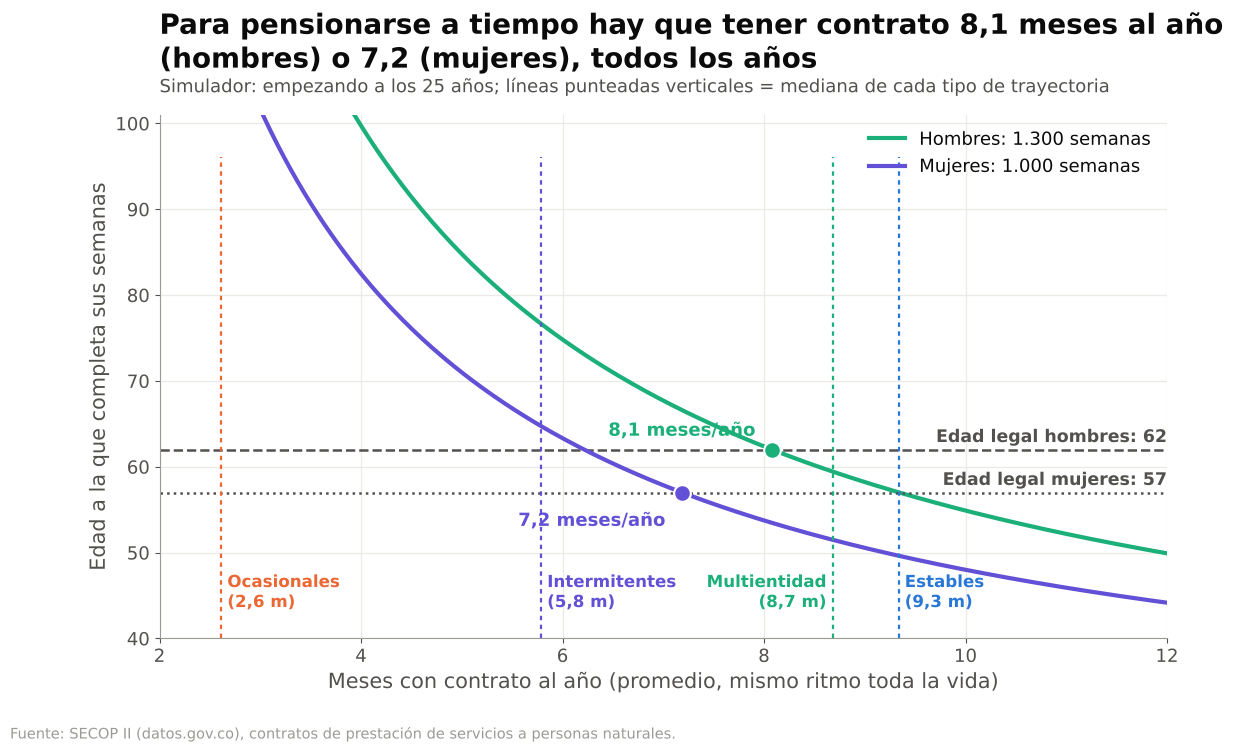

In [15]:
# Figura 4: el simulador en una gráfica — edad de llegada según los meses de contrato al año
fig, ax = plt.subplots(figsize=(13, 6.8))
meses = np.linspace(2, 12, 300)
for g in ['Hombre', 'Mujer']:
    e_l = EDAD_LEGAL[g]
    edad = EDAD_INICIO + SEMANAS_EXIGIDAS[g] / (meses * SEMANAS_POR_MES)
    ax.plot(meses, edad, color=COL_GENERO[g], lw=3, label=f'{PLURAL[g]}: {num(SEMANAS_EXIGIDAS[g])} semanas')
    ax.axhline(e_l, color=COLOR['tinta2'], ls=LINEA_LEGAL[g], lw=1.8)
    ax.text(12, e_l + 0.4, f'Edad legal {PLURAL[g].lower()}: {e_l}', fontsize=12.5, color=COLOR['tinta2'],
            fontweight='bold', va='bottom', ha='right')
    ax.plot(MESES_REQ[g], e_l, 'o', color=COL_GENERO[g], ms=12, zorder=4, markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(f'{num(MESES_REQ[g], 1)} meses/año', (MESES_REQ[g], e_l), xytext=(-12, 10 if g == 'Hombre' else -24),
                textcoords='offset points', fontsize=13, color=COL_GENERO[g], fontweight='bold', ha='right')
alturas = {'Estables': 43, 'Multientidad': 43, 'Intermitentes': 43, 'Ocasionales': 43}
lado = {'Estables': ('left', 0.06), 'Multientidad': ('right', -0.06), 'Intermitentes': ('left', 0.06), 'Ocasionales': ('left', 0.06)}
for n in ORDEN:
    m = P.loc[P.nombre_cluster == n, 'meses_por_anio_obs'].median()
    ax.axvline(m, color=COL_CLUSTER[n], ls=(0, (2, 2)), lw=1.6, ymax=0.92)
    ax.text(m + lado[n][1], alturas[n], f'{n}\n({num(m, 1)} m)', fontsize=12, color=COL_CLUSTER[n], fontweight='bold',
            va='bottom', ha=lado[n][0])
ax.set_xlim(2, 12); ax.set_ylim(40, EDAD_TOPE_GRAFICA + 1)
ax.set_xlabel('Meses con contrato al año (promedio, mismo ritmo toda la vida)')
ax.set_ylabel('Edad a la que completa sus semanas')
ax.grid(True, axis='both'); ax.legend(loc='upper right')
titulo(ax, f'Para pensionarse a tiempo hay que tener contrato {num(MESES_REQ["Hombre"], 1)} meses al año (hombres) '
           f'o {num(MESES_REQ["Mujer"], 1)} (mujeres), todos los años',
       'Simulador: empezando a los 25 años; líneas punteadas verticales = mediana de cada tipo de trayectoria', ancho=66)
fuente(fig); guardar(fig, '05_simulador_curva'); plt.show()

## 3. Casos reales anonimizados (k ≥ 10)

Elegimos una persona real de **Estables**, **Intermitentes** y **Ocasionales**:
- **Cerca de la mediana** de su cluster en meses por año y en honorario (distancia normalizada por el rango
  intercuartílico de cada variable).
- Con presencia en **al menos 3 de los 4 años** 2022–2025 cuando el cluster lo permite (si no, 2 y luego 1).
- Con género definido, porque la proyección depende de la edad legal y de las semanas exigidas.
- Entre los cercanos, el más **típico** de su cluster también en meses por año activo, contratos por año y huecos
  por año (pesan la mitad que los dos criterios principales).
- Si los tres salen hombres, se cambia el caso donde la mejor candidata mujer pierde menos tipicidad, para que haya
  al menos una mujer.

**Anonimización (k ≥ 10).** SECOP II es público **con el nombre del contratista**, así que no basta con quitar los
identificadores: el patrón publicado no puede apuntar a una sola persona. Solo se publica una **firma gruesa**:
- meses cubiertos por año **redondeados al mes** (mínimo 1 si hubo contrato);
- contratos por año con tope **"2+"**;
- honorario mensual mediano redondeado a **$500.000**;
- género y cluster.

Exigimos que **al menos 10 personas** del universo (848 mil contratistas) compartan exactamente esa firma. **No** se
publica entidad, `id_persona`, fechas, departamento ni objeto del contrato. Si en un cluster no hubiera ningún
candidato con k ≥ 10, se usaría un **caso tipo** construido con las medianas del cluster y se rotularía así.

In [16]:
ANIOS = [2022, 2023, 2024, 2025]
K_MIN = 10
REDONDEO_HONORARIO = 500_000
TOPE_CONTRATOS = 2
Mw = pa.pivot(index='id_persona', columns='anio', values='meses_cubiertos').reindex(columns=ANIOS)
Cw = pa.pivot(index='id_persona', columns='anio', values='n_contratos').reindex(columns=ANIOS).fillna(0).astype(int)
# Meses redondeados al mes; si tuvo contrato ese año se muestra al menos 1 para que no parezca un año vacío
Mr = np.round(Mw).where(Mw.isna(), np.maximum(np.round(Mw), 1)).fillna(0).astype(int)
Cr = Cw.clip(upper=TOPE_CONTRATOS)
Hr = (np.round(P.honorario_mediano / REDONDEO_HONORARIO) * REDONDEO_HONORARIO).astype(int)
firma = pd.concat([Mr.add_prefix('m_'), Cr.add_prefix('c_')], axis=1).reindex(P.index)
firma['h'] = Hr; firma['g'] = P.genero
clave = pd.util.hash_pandas_object(firma, index=False)
k_firma = clave.map(clave.value_counts())
k_firma.index = P.index
print(f'Con la firma gruesa: {pct((k_firma == 1).mean())} de las personas son únicas (k = 1) y '
      f'{pct((k_firma >= K_MIN).mean())} tienen k ≥ {K_MIN}')

CLUSTERS_CASO = ['Estables', 'Intermitentes', 'Ocasionales']
rng = np.random.default_rng(SEMILLA)
seleccion, pools = {}, {}
for n in CLUSTERS_CASO:
    g = P[P.nombre_cluster == n]
    med_m, med_h = g.meses_por_anio_obs.median(), g.honorario_mediano.median()
    iqr_m = g.meses_por_anio_obs.quantile(.75) - g.meses_por_anio_obs.quantile(.25)
    lh = np.log(g.honorario_mediano)
    iqr_h = lh.quantile(.75) - lh.quantile(.25)
    dist = (g.meses_por_anio_obs - med_m).abs() / iqr_m + (lh - np.log(med_h)).abs() / iqr_h
    # "Tipicidad" secundaria: que también se parezca a su cluster en meses por año activo, contratos y huecos por año
    def d_rel(c):
        q = g[c].quantile([.25, .5, .75]).values
        return (g[c] - q[1]).abs() / max(q[2] - q[0], 1e-9)
    tipico = d_rel('meses_prom_activo') + d_rel('n_contratos_prom') + d_rel('huecos_prom')
    pool, usado = None, None
    for min_anios in (3, 2, 1):
        base = g[(g.anios_activos >= min_anios) & (g.genero != 'No definido') & (k_firma.loc[g.index] >= K_MIN)]
        for umbral_d in (0.10, 0.20, 0.30):
            c = base[dist.loc[base.index] <= umbral_d]
            if len(c):
                pool, usado = c, (min_anios, umbral_d)
                break
        if pool is not None:
            break
    info = {'med_m': med_m, 'med_h': med_h, 'med_contratos': g.n_contratos_prom.median()}
    if pool is None:
        seleccion[n] = {'id': None, 'tipo': 'caso tipo', **info}
        print(f'{n}: ningún candidato con k ≥ {K_MIN} → se usará un caso tipo con las medianas del cluster')
        continue
    pool = pool.assign(dist=dist.loc[pool.index], tip=tipico.loc[pool.index], k=k_firma.loc[pool.index],
                       azar=rng.random(len(pool)))
    pool['puntaje'] = pool.dist + 0.5 * pool.tip
    pool = pool.sort_values(['puntaje', 'azar'])
    pools[n] = pool
    seleccion[n] = {'id': pool.index[0], 'tipo': 'real', 'min_anios': usado[0], 'umbral_distancia': usado[1],
                    'candidatos': int(len(pool)), 'pct_cluster_con_min_anios': float((g.anios_activos >= usado[0]).mean()), **info}

# Al menos una mujer: si todos los elegidos son hombres, cambiamos donde la mejor mujer pierde menos puntaje
generos_sel = [P.loc[s['id'], 'genero'] for s in seleccion.values() if s['id'] is not None]
if 'Mujer' not in generos_sel:
    costo = {n: pl[pl.genero == 'Mujer'].puntaje.iloc[0] - pl.puntaje.iloc[0] for n, pl in pools.items()
             if (pl.genero == 'Mujer').any()}
    if costo:
        n_cambio = min(costo, key=costo.get)
        seleccion[n_cambio]['id'] = pools[n_cambio][pools[n_cambio].genero == 'Mujer'].index[0]
        print(f'Para incluir una mujer se cambió el caso de {n_cambio} (costo en puntaje: {costo[n_cambio]:.3f})')
for n, s_ in seleccion.items():
    if s_['id'] is not None:
        print(f'{n}: {s_["candidatos"]:,} candidatos (≥{s_["min_anios"]} años, distancia ≤ {s_["umbral_distancia"]}) · '
              f'firma compartida por {k_firma[s_["id"]]} personas · {P.loc[s_["id"], "genero"]}')

Con la firma gruesa: 23,0% de las personas son únicas (k = 1) y 55,3% tienen k ≥ 10


Estables: 36 candidatos (≥3 años, distancia ≤ 0.1) · firma compartida por 10 personas · Mujer
Intermitentes: 7 candidatos (≥3 años, distancia ≤ 0.1) · firma compartida por 18 personas · Mujer
Ocasionales: 174 candidatos (≥2 años, distancia ≤ 0.1) · firma compartida por 10 personas · Mujer


In [17]:
casos = []
for i, n in enumerate(CLUSTERS_CASO, start=1):
    s_ = seleccion[n]
    if s_['tipo'] == 'real':
        pid = s_['id']; gen = P.loc[pid, 'genero']
        meses = {a: int(Mr.loc[pid, a]) for a in ANIOS}
        contratos = {a: int(Cr.loc[pid, a]) for a in ANIOS}
        hon = int(Hr.loc[pid]); k = int(k_firma.loc[pid])
    else:                                    # caso tipo: medianas del cluster (no es una persona real)
        gen = 'Mujer'
        meses = {a: int(round(s_['med_m'])) for a in ANIOS}
        contratos = {a: int(min(round(s_['med_contratos']), TOPE_CONTRATOS)) for a in ANIOS}
        hon = int(round(s_['med_h'] / REDONDEO_HONORARIO) * REDONDEO_HONORARIO); k = None
    primer = min(a for a in ANIOS if contratos[a] > 0)
    anios_obs = [a for a in ANIOS if a >= primer]
    meses_prom = float(np.mean([meses[a] for a in anios_obs]))      # se calcula con los valores ya redondeados
    proy = cuando_me_pensiono(meses_por_anio=meses_prom, honorario_mensual=hon, semanas_actuales=0,
                              edad_actual=EDAD_INICIO, genero=gen, n_entidades=1)
    caso = {
        'caso': i, 'tipo': 'trayectoria real anonimizada' if s_['tipo'] == 'real' else 'caso tipo (medianas del cluster, no es una persona)',
        'cluster': n, 'genero': gen,
        'anios_con_contrato_2022_2025': int(sum(c > 0 for c in contratos.values())),
        'meses_cubiertos_por_anio': {str(a): v for a, v in meses.items()},
        'contratos_por_anio': {str(a): v for a, v in contratos.items()},
        'honorario_mensual_redondeado': hon,
        'meses_por_anio_promedio': round(meses_prom, 2),
        'referencia_cluster': {'mediana_meses_por_anio': round(float(s_['med_m']), 2),
                               'mediana_honorario_redondeada': int(round(s_['med_h'] / 1e5) * 1e5)},
        'personas_con_la_misma_firma_redondeada': k,
        'proyeccion_simulador': {**proy, 'supuesto': f'mismo ritmo desde los {EDAD_INICIO} años, sin semanas previas'},
    }
    if gen == 'Mujer':
        caso['proyeccion_si_1300_semanas'] = cuando_me_pensiono(meses_prom, hon, 0, EDAD_INICIO, gen,
                                                                semanas_requeridas=1300)['edad_a_la_que_llega']
    if s_['tipo'] == 'real':
        caso['referencia_cluster'].update({'criterio_presencia': f'al menos {s_["min_anios"]} de 4 años',
                                           'pct_del_cluster_que_cumple_presencia': round(s_['pct_cluster_con_min_anios'], 3)})
    casos.append(caso)

# Verificación de anonimización: k ≥ 10 y ninguna llave ni dato sensible en la salida
assert all(c['personas_con_la_misma_firma_redondeada'] is None or c['personas_con_la_misma_firma_redondeada'] >= K_MIN for c in casos)
texto_casos = json.dumps(a_python(casos), ensure_ascii=False)
assert not any(str(s_['id']) in texto_casos for s_ in seleccion.values() if s_['id'] is not None), 'Se filtró un id_persona'
def llaves(x):
    if isinstance(x, dict):
        return [k for k in x] + [kk for v in x.values() for kk in llaves(v)]
    if isinstance(x, list):
        return [kk for v in x for kk in llaves(v)]
    return []
for prohibida in ('nit', 'entidad', 'departamento', 'objeto', 'fecha', 'id_persona', 'ciudad'):
    assert not any(prohibida in str(k).lower() for k in llaves(a_python(casos)) if k not in ORDEN), prohibida
CASOS_JSON.write_text(json.dumps(a_python({
    'descripcion': 'Tres trayectorias de SECOP II (2022–2025), anonimizadas con k ≥ 10: al menos 10 contratistas comparten '
                   'exactamente la firma publicada. Sin entidad, id, fechas, departamento ni objeto. Meses redondeados al mes '
                   '(mínimo 1 si hubo contrato); contratos por año con tope 2 ("2" significa 2 o más); honorario mensual '
                   'mediano redondeado a $500.000. Semanas exigidas: 1.300 hombres, 1.000 mujeres (C-197 de 2023).',
    'k_minimo': K_MIN,
    'casos': casos}), ensure_ascii=False, indent=2), encoding='utf-8')
print('Casos guardados en', CASOS_JSON)
seleccion = {n: {k: v for k, v in s_.items() if k != 'id'} for n, s_ in seleccion.items()}   # se descarta el id
pd.DataFrame([{'caso': c['caso'], 'tipo': c['tipo'][:13], 'cluster': c['cluster'], 'genero': c['genero'],
               **{f'meses_{a}': m for a, m in c['meses_cubiertos_por_anio'].items()},
               **{f'contratos_{a}': m for a, m in c['contratos_por_anio'].items()}, 'honorario': c['honorario_mensual_redondeado'],
               'semanas_req': c['proyeccion_simulador']['semanas_requeridas'],
               'edad_llega': c['proyeccion_simulador']['edad_a_la_que_llega'], 'edad_legal': c['proyeccion_simulador']['edad_legal'],
               'k_firma': c['personas_con_la_misma_firma_redondeada']} for c in casos])

Casos guardados en ../outputs/casos_reales.json


,caso,tipo,cluster,genero,meses_2022,meses_2023,meses_2024,meses_2025,contratos_2022,contratos_2023,contratos_2024,contratos_2025,honorario,semanas_req,edad_llega,edad_legal,k_firma
0,1,trayectoria r,Estables,Mujer,12,12,12,2,2,2,1,1,4000000,1000,49.2,57,10
1,2,trayectoria r,Intermitentes,Mujer,11,11,1,0,2,2,1,0,3000000,1000,65.0,57,18
2,3,trayectoria r,Ocasionales,Mujer,3,7,0,0,1,1,0,0,3500000,1000,117.0,57,10


Figura guardada: ../outputs/figs/05_casos_reales.png


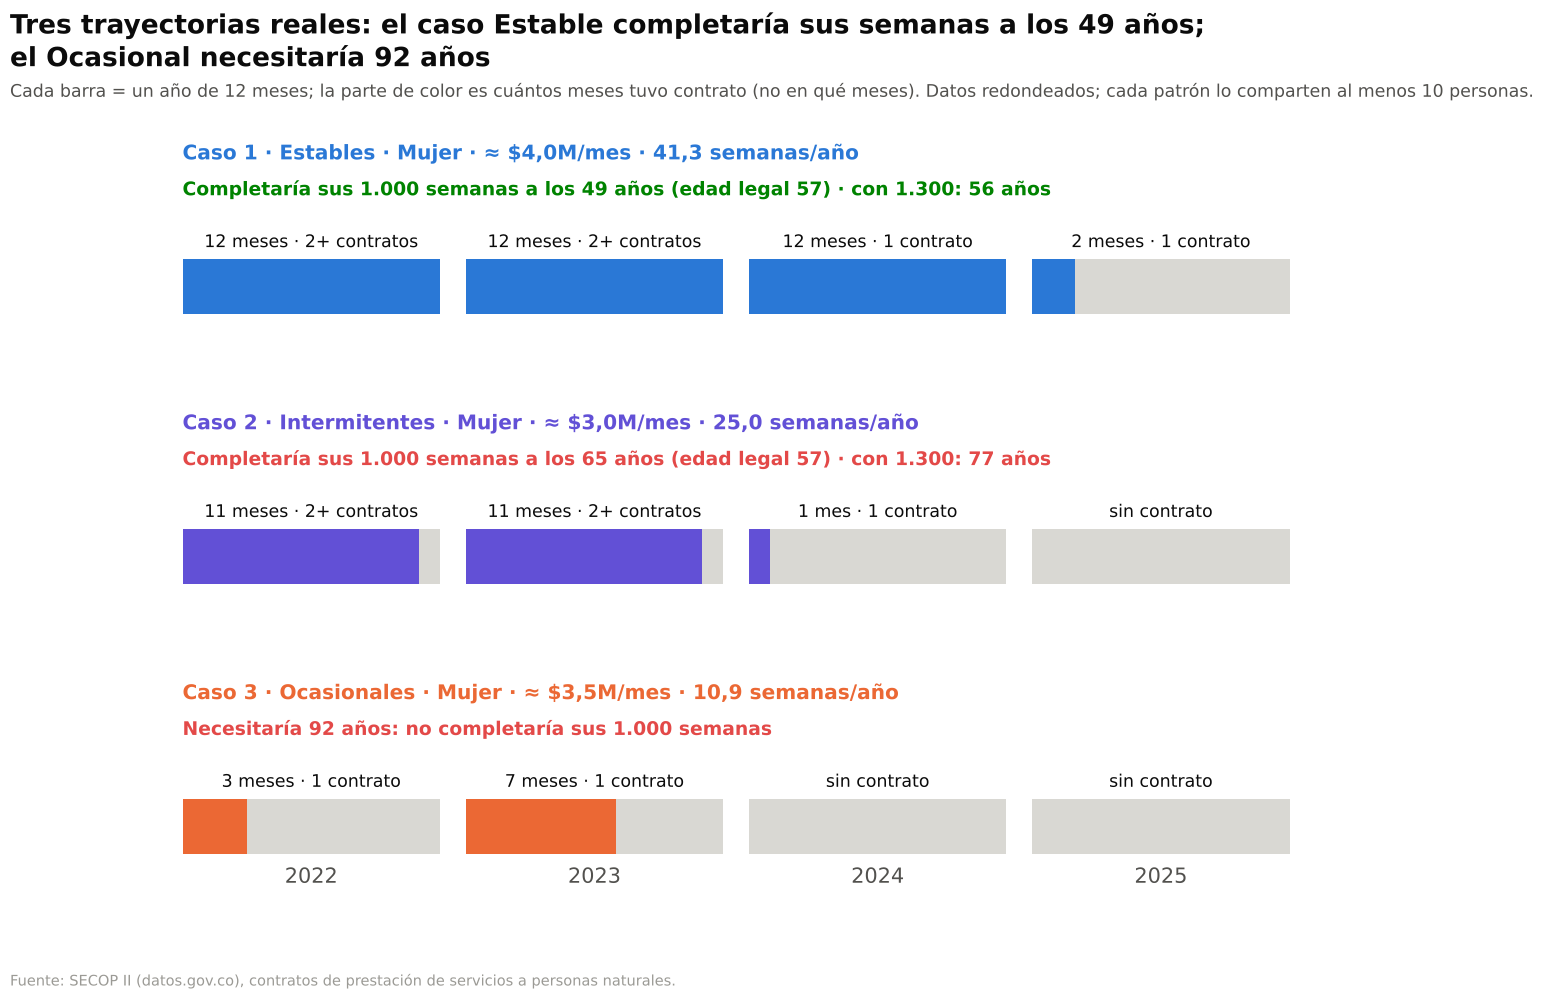

In [18]:
# Figura 5: línea de tiempo de cada caso (cuántos meses cubrió cada año, no en qué meses)
fig, axs = plt.subplots(len(casos), 1, figsize=(15, 8.6), sharex=True)
ANCHO = 12; SEP = 1.2
for ax, c in zip(axs, casos):
    col = COL_CLUSTER[c['cluster']]
    for j, a in enumerate(ANIOS):
        x0 = j * (ANCHO + SEP)
        m = c['meses_cubiertos_por_anio'][str(a)]; k = c['contratos_por_anio'][str(a)]
        ax.barh(0, ANCHO, left=x0, height=0.62, color=COLOR['gris_claro'])
        ax.barh(0, m, left=x0, height=0.62, color=col)
        ktxt = '2+ contratos' if k >= TOPE_CONTRATOS else f'{k} contrato'
        txt = f'{m} {"mes" if m == 1 else "meses"} · {ktxt}' if k else 'sin contrato'
        ax.text(x0 + ANCHO / 2, 0.40, txt, ha='center', va='bottom', fontsize=12.5, color=COLOR['tinta'])
    p = c['proyeccion_simulador']
    llega = p['edad_a_la_que_llega']
    req = num(p['semanas_requeridas'])
    veredicto = (f'Completaría sus {req} semanas a los {num(llega, 0)} años (edad legal {p["edad_legal"]})'
                 if llega <= 110 else f'Necesitaría {num(p["anios_que_faltan"], 0)} años: no completaría sus {req} semanas')
    if 'proyeccion_si_1300_semanas' in c and llega <= 110:
        veredicto += f' · con 1.300: {num(c["proyeccion_si_1300_semanas"], 0)} años'
    etiqueta_tipo = '' if c['tipo'].startswith('trayectoria') else ' · CASO TIPO'
    ax.text(0, 1.38, f'Caso {c["caso"]} · {c["cluster"]} · {c["genero"]} · ≈ ${num(c["honorario_mensual_redondeado"] / 1e6, 1)}M/mes · '
                     f'{num(p["semanas_por_anio"], 1)} semanas/año{etiqueta_tipo}', fontsize=14.5, fontweight='bold',
            color=col, va='bottom')
    ax.text(0, 0.98, veredicto, ha='left', va='bottom', fontsize=13.5,
            color=COLOR['rojo'] if not p['llega_antes_de_edad_legal'] else COLOR['verde'], fontweight='bold')
    ax.set_ylim(-0.4, 1.85); ax.set_yticks([]); ax.grid(False); ax.tick_params(axis='x', length=0)
    for sp in ('left', 'bottom'): ax.spines[sp].set_visible(False)
axs[-1].set_xticks([j * (ANCHO + SEP) + ANCHO / 2 for j in range(len(ANIOS))])
axs[-1].set_xticklabels([str(a) for a in ANIOS], fontsize=15); axs[-1].tick_params(length=0)
peor = casos[-1]['proyeccion_simulador']; mejor = casos[0]['proyeccion_simulador']
fig.suptitle(textwrap.fill(f'Tres trayectorias reales: el caso Estable completaría sus semanas a los '
             f'{num(mejor["edad_a_la_que_llega"], 0)} años; el Ocasional necesitaría {num(peor["anios_que_faltan"], 0)} años', 80),
             x=0.01, ha='left', va='bottom', fontsize=19, fontweight='bold', y=1.025)
fig.text(0.01, 0.995, 'Cada barra = un año de 12 meses; la parte de color es cuántos meses tuvo contrato (no en qué meses). '
                      f'Datos redondeados; cada patrón lo comparten al menos {K_MIN} personas.', fontsize=12.5,
         color=COLOR['tinta2'], va='bottom')
fig.subplots_adjust(hspace=0.35, top=0.97)
fuente(fig); guardar(fig, '05_casos_reales'); plt.show()

## 4. Limitaciones

- **Los tiempos son una COTA SUPERIOR.** SECOP II solo muestra contratos de prestación de servicios con el
  Estado. No vemos el **empleo formal** (con el Estado o con privados) que una persona pudo tener entre contratos,
  ni sus contratos registrados en **SECOP I**, ni trabajos independientes con privados. Todo eso también cotiza. Un
  mes "sin contrato" en SECOP II no es necesariamente un mes sin cotizar, así que las semanas reales pueden ser más
  y los años hasta completarlas, menos.
- **Cobertura baja de SECOP II en 2020–2021.** En esos años muchas entidades seguían publicando en SECOP I (ver la
  tabla de abajo: hay muchas menos personas activas). Por eso las trayectorias se miden en 2022–2025 y 2020–2021 solo
  se usan como antigüedad.
- **Ventana corta para una proyección larga.** Extrapolamos 4 años de comportamiento a 30–40 años de vida laboral.
  Las trayectorias cambian: un Ocasional joven puede volverse Estable, o salir a un empleo formal.
- **Censura.** Quien aparece por primera vez en 2025 tiene un solo año observable; muchos caen en Ocasionales porque
  todavía no sabemos si van a continuar. Eso infla el tiempo estimado de ese grupo.
- **Contrato no es lo mismo que cotización pagada.** Suponemos que cada semana con contrato se cotiza. Si una
  persona no paga la planilla o la paga tarde, sus semanas reales serán menos. En esto la cota va en sentido contrario.
- **Conversión a semanas.** Usamos días / 7 (52,1 semanas por año completo). Colpensiones cuenta meses de 30 días
  (unas 51,4 semanas por año), así que las semanas podrían estar sobreestimadas en cerca de 1,4%.
- **Regla de semanas para mujeres.** El escenario principal usa 1.000 semanas para mujeres (Sentencia C-197 de 2023:
  1.250 en 2026 y 25 menos cada año hasta 1.000 en 2036). Una mujer que se pensione antes de 2036 necesita más de
  1.000. La sensibilidad con 1.300 para todos acota el resultado por el otro lado. Conviene verificar la norma vigente
  antes de presentar.
- **Supuestos fijos del ejercicio:** inicio a los 25 años y SMMLV de 2025. No estimamos el **monto** de la pensión,
  solo si se alcanzan las semanas.

In [19]:
cob_anio = cob.groupby('anio').size().rename('personas_activas').to_frame()
cob_anio['vs_2025'] = cob_anio.personas_activas / cob_anio.loc[2025, 'personas_activas']
guardar_tabla(cob_anio, '05_cobertura_por_anio')
cob_anio.style.format({'personas_activas': lambda v: num(v), 'vs_2025': lambda v: pct(v, 0)})

Tabla guardada: ../outputs/tablas/05_cobertura_por_anio.csv


,personas_activas,vs_2025
anio,,
2020,210.496,41%
2021,325.660,63%
2022,402.755,78%
2023,437.494,85%
2024,471.549,92%
2025,513.680,100%


## 5. Guardar resultados
`outputs/resultados_05.json` (cifras clave y parámetros del simulador) y `outputs/RESUMEN_05.md` (resumen en
español sencillo). No se modifica `outputs/resultados.json`, que pertenece a los notebooks 01–04.

In [20]:
def filas(df):
    return {str(i): {k: a_python(v) for k, v in f.items()} for i, f in df.iterrows()}

FIGURAS = {
    '05_edad_pension_por_cluster.png': 'Edad mediana a la que cada tipo de trayectoria completaría sus semanas (hombres 1.300, mujeres 1.000), con rango intercuartílico y edades legales.',
    '05_semanas_requeridas.png': '% de contratistas que cotiza al menos X semanas por año, con los umbrales de hombres (35,1), mujeres con la regla vigente (31,3) y mujeres con 1.300 (40,6, sensibilidad).',
    '05_a_tiempo_por_genero.png': '% que completa sus semanas a la edad legal, por tipo de trayectoria y género, con la sensibilidad de 1.300 semanas para mujeres.',
    '05_pension_por_decil.png': '% que llega a tiempo y edad mediana de llegada por decil de riesgo del modelo del notebook 04 (D1 = mayor riesgo).',
    '05_simulador_curva.png': 'Curvas del simulador (hombres 1.300, mujeres 1.000): edad de llegada según los meses de contrato al año, con la mediana de cada cluster.',
    '05_casos_reales.png': 'Línea de tiempo 2022–2025 de los tres casos reales anonimizados (k ≥ 10) y su proyección.',
}
FIGURAS = {k: v for k, v in FIGURAS.items() if (FIGS / k).exists()}
sem_cluster = tab_cluster.loc[ORDEN, 'semanas_anio_mediana']
resultados_05 = {
    'supuestos': {'edad_inicio': EDAD_INICIO, 'edad_legal': EDAD_LEGAL,
                  'semanas_exigidas_principal': SEMANAS_EXIGIDAS, 'semanas_exigidas_sensibilidad': SEMANAS_EXIGIDAS_SENS,
                  'fuente_semanas_mujeres': 'Sentencia C-197 de 2023 (Corte Constitucional): 1.250 en 2026, -25 por año, 1.000 desde 2036',
                  'semanas_por_anio_requeridas': SEMANAS_REQ, 'meses_por_anio_requeridos': MESES_REQ,
                  'semanas_por_anio_requeridas_sensibilidad': SEMANAS_REQ_SENS, 'meses_por_anio_requeridos_sensibilidad': MESES_REQ_SENS,
                  'medida_de_ritmo': 'semanas_por_anio_obs = dias con contrato 2022-2025 / 7 / anios observables (notebook 03)'},
    'por_cluster': filas(tab_cluster),
    'por_cluster_y_genero': {f'{c} | {g}': {k: a_python(v) for k, v in f.items()} for (c, g), f in tab_genero.iterrows()},
    'escenarios_genero_pct_a_tiempo': filas(escenarios),
    'pct_todos_supera_umbral': {**{g: float((P.semanas_por_anio_obs >= SEMANAS_REQ[g]).mean()) for g in EDAD_LEGAL},
                                'Mujer_con_1300': float(sup_sens_m)},
    'por_decil_riesgo': filas(tab_decil) if RIESGO_OK else 'PENDIENTE: no existía data_intermedia/riesgo_2024_2025.parquet al ejecutar',
    'deciles_info': {**info_decil, 'convencion': 'D1 = mayor riesgo (menor probabilidad de continuidad)'},
    'chequeo_vs_notebook_03': filas(chequeo),
    'simulador': {
        'firma': 'cuando_me_pensiono(meses_por_anio, honorario_mensual, semanas_actuales=0, edad_actual=25, genero="Hombre", n_entidades=1, semanas_requeridas=None)',
        'semanas_requeridas_por_genero': SEMANAS_EXIGIDAS,
        'smmlv_usado': {'anio': ANIO_SMMLV_SIM, 'valor': SMMLV_SIM},
        'smmlv_tabla': {a: SMMLV[a] for a in (2022, 2023, 2024, 2025)},
        'fraccion_ibc': FRACCION_IBC, 'tasa_cotizacion_pension': TASA_PENSION, 'semanas_por_mes': SEMANAS_POR_MES,
        'semanas_por_anio_por_cluster_mediana': {n: float(v) for n, v in sem_cluster.items()},
        'arbol': {'profundidad_max': 3, 'min_samples_leaf': 500, 'class_weight': 'balanced',
                  'variables': list(XA.columns), 'particion': '80/20 estratificada, semilla 42',
                  'exactitud': met_arbol['exactitud'], 'exactitud_balanceada': met_arbol['exactitud_balanceada'],
                  'sin_pesos': met_sin, 'sensibilidad_con_contratos_por_anio': met_con_contratos,
                  'matriz_confusion_normalizada': filas(cm),
                  'importancia_variables': IMPORTANCIA_ARBOL,
                  'reglas_texto': REGLAS_TEXTO, 'reglas_simplificadas': REGLAS},
        'ejemplos': tab_ej.to_dict('records')},
    'casos_reales': {'archivo': 'outputs/casos_reales.json', 'k_minimo': K_MIN,
                     'k_por_caso': [c['personas_con_la_misma_firma_redondeada'] for c in casos],
                     'tipo_por_caso': [c['tipo'] for c in casos]},
    'cobertura_personas_por_anio': {int(a): int(v) for a, v in cob_anio.personas_activas.items()},
    'figuras': FIGURAS,
}
RESULTADOS_05.write_text(json.dumps(a_python(resultados_05), ensure_ascii=False, indent=2), encoding='utf-8')
print('Guardado:', RESULTADOS_05)

Guardado: ../outputs/resultados_05.json


In [21]:
# RESUMEN_05.md: hallazgos en español sencillo (se arma con las cifras de este notebook)
tc = tab_cluster
def fila_md(n):
    f = tc.loc[n]
    return (f'| {n} | {num(f.personas)} | {num(f.semanas_anio_mediana, 1)} | {num(f.anios_1300_mediana, 0)} | '
            f'{num(f.edad_llega_mediana, 0)} | {pct(f.pct_llega_a_tiempo, 0)} | {pct(f.pct_llega_a_tiempo_1300_todos, 0)} | '
            f'{pct(f.pct_no_llega_ni_a_80, 0)} |')
tabla_md = '\n'.join(['| Tipo de trayectoria | Personas | Semanas/año (mediana) | Años hasta 1.300 semanas | '
                      'Edad de llegada (regla vigente) | Llega a tiempo (regla vigente) | Llega a tiempo (1.300 para todos) | '
                      'No llega ni a los 80 |',
                      '|---|---:|---:|---:|---:|---:|---:|---:|'] + [fila_md(n) for n in ORDEN + ['Total']])
tg = tab_genero
gen_md = '\n'.join(['| Tipo | Hombres (1.300): edad de llegada | Hombres: a tiempo (62) | Mujeres (1.000): edad de llegada | '
                    'Mujeres: a tiempo (57) | Mujeres con 1.300: a tiempo |',
                    '|---|---:|---:|---:|---:|---:|'] +
                   [f'| {n} | {num(tg.loc[(n, "Hombre"), "edad_llega_mediana"], 0)} | {pct(tg.loc[(n, "Hombre"), "pct_llega_a_tiempo"], 0)} | '
                    f'{num(tg.loc[(n, "Mujer"), "edad_llega_mediana"], 0)} | {pct(tg.loc[(n, "Mujer"), "pct_llega_a_tiempo"], 0)} | '
                    f'{pct(tg.loc[(n, "Mujer"), "pct_llega_a_tiempo_1300_todos"], 0)} |'
                    for n in ORDEN + ['Total']])
if RIESGO_OK:
    td = tab_decil
    d_alto, d_bajo = td.index[0], td.index[-1]
    decil_md = (f'- **Por decil de riesgo (modelo del 04, D1 = mayor riesgo):** en D{d_alto} llega a tiempo '
                f'**{pct(td.loc[d_alto, "pct_llega_a_tiempo"], 0)}** y la edad mediana de llegada es '
                f'{num(td.loc[d_alto, "edad_llega_mediana"], 0)} años; en D{d_bajo}, '
                f'**{pct(td.loc[d_bajo, "pct_llega_a_tiempo"], 0)}** y {num(td.loc[d_bajo, "edad_llega_mediana"], 0)} años. '
                f'El riesgo de corto plazo que predice el modelo se traduce en riesgo pensional.')
else:
    decil_md = '- **Por decil de riesgo:** PENDIENTE (no existía `riesgo_2024_2025.parquet` al ejecutar).'
def caso_md(c):
    p = c['proyeccion_simulador']
    m = ' · '.join(f'{a}: {v} m ({"2+" if c["contratos_por_anio"][a] >= TOPE_CONTRATOS else c["contratos_por_anio"][a]} c)'
                   for a, v in c['meses_cubiertos_por_anio'].items())
    req = num(p['semanas_requeridas'])
    lleg = (f'completaría sus {req} semanas a los **{num(p["edad_a_la_que_llega"], 0)} años** (edad legal {p["edad_legal"]})'
            if p['edad_a_la_que_llega'] <= 110 else f'necesitaría **{num(p["anios_que_faltan"], 0)} años**: no llegaría')
    extra = (f' Con 1.300 semanas llegaría a los {num(c["proyeccion_si_1300_semanas"], 0)}.'
             if 'proyeccion_si_1300_semanas' in c and c['proyeccion_si_1300_semanas'] <= 110 else '')
    tipo = '' if c['tipo'].startswith('trayectoria') else ' — **caso tipo, no es una persona real**'
    kk = f'; patrón compartido por {c["personas_con_la_misma_firma_redondeada"]} personas' if c['personas_con_la_misma_firma_redondeada'] else ''
    return (f'{c["caso"]}. **{c["cluster"]} ({c["genero"]})**{tipo}, honorario ≈ ${num(c["honorario_mensual_redondeado"] / 1e6, 1)}M/mes '
            f'({"cotiza sobre 1 SMMLV" if p["cotiza_sobre_minimo"] else "cotiza sobre el 40% del honorario"}{kk}). {m}. '
            f'Ritmo: {num(p["semanas_por_anio"], 1)} semanas/año → empezando a los 25, {lleg}.{extra} '
            f'A la edad legal tendría {num(p["semanas_a_la_edad_legal"], 0)} semanas.')
est, inter, ocas = tc.loc['Estables'], tc.loc['Intermitentes'], tc.loc['Ocasionales']
sup_h, sup_m = resultados_05['pct_todos_supera_umbral']['Hombre'], resultados_05['pct_todos_supera_umbral']['Mujer']
th, tm, tm_s = tot.loc['Hombre', 'pct_llega_a_tiempo'], tot.loc['Mujer', 'pct_llega_a_tiempo'], tot.loc['Mujer', 'pct_llega_a_tiempo_1300_todos']
eh, em = tg.loc[('Estables', 'Hombre'), 'pct_llega_a_tiempo'], tg.loc[('Estables', 'Mujer'), 'pct_llega_a_tiempo']
em_s = tg.loc[('Estables', 'Mujer'), 'pct_llega_a_tiempo_1300_todos']
md_txt = f"""# Resumen del notebook 05 · ¿Cuándo se pensionaría un contratista?

**Pregunta:** si un contratista de prestación de servicios del Estado empieza a cotizar a los 25 años y mantiene el
ritmo de contratos que tuvo en SECOP II entre 2022 y 2025, ¿a qué edad completaría las semanas de la pensión?

**Regla usada (escenario principal):** hombres 1.300 semanas y edad legal 62; mujeres **1.000 semanas** y edad legal
57. Esto sale de la Sentencia C-197 de 2023 de la Corte Constitucional: desde 2026 las mujeres necesitan 1.250 semanas
y el requisito baja 25 por año hasta 1.000 en 2036. Para quien empieza hoy a los 25, la regla relevante es 1.000.
**Sensibilidad:** 1.300 semanas para todos.

## Hallazgos principales
- **El total:** la mitad de los {num(tc.loc['Total', 'personas'])} contratistas cotiza menos de
  {num(tc.loc['Total', 'semanas_anio_mediana'], 1)} semanas al año. A ese ritmo necesitaría
  {num(tc.loc['Total', 'anios_1300_mediana'], 0)} años para juntar 1.300 semanas. Con la regla vigente, solo
  **{pct(tc.loc['Total', 'pct_llega_a_tiempo'], 0)}** de quienes tienen género definido completaría sus semanas a su edad legal.
- **El umbral:** un hombre necesita contrato **{num(MESES_REQ['Hombre'], 1)} meses al año** ({num(SEMANAS_REQ['Hombre'], 1)} semanas)
  todos los años desde los 25; una mujer, **{num(MESES_REQ['Mujer'], 1)} meses** ({num(SEMANAS_REQ['Mujer'], 2)} semanas). Lo
  cumple el {pct(sup_h, 0)} de todos los contratistas con el umbral de hombres y el {pct(sup_m, 0)} con el de mujeres.
- **Estables** ({num(est.semanas_anio_mediana, 1)} semanas/año): completarían sus semanas hacia los
  **{num(est.edad_llega_mediana, 0)} años** y {pct(est.pct_llega_a_tiempo, 0)} llega a tiempo. Junto con **Multientidad**
  ({pct(tc.loc['Multientidad', 'pct_llega_a_tiempo'], 0)} a tiempo, un grupo pequeño), son los únicos que se acercan a la pensión.
- **Intermitentes** ({num(inter.semanas_anio_mediana, 1)} semanas/año): necesitarían {num(inter.anios_1300_mediana, 0)} años
  para 1.300 semanas. Solo {pct(inter.pct_llega_a_tiempo, 0)} llega a tiempo.
- **Ocasionales** ({num(ocas.semanas_anio_mediana, 1)} semanas/año): necesitarían {num(ocas.anios_1300_mediana, 0)} años para
  1.300 semanas (y {num(tg.loc[('Ocasionales', 'Mujer'), 'anios_requisito_mediana'], 0)} para 1.000). En la práctica **no se
  pensionan** con contratos del Estado. Son el grupo más grande ({pct(ocas.personas / tc.loc['Total', 'personas'], 0)}).
- **Género: la conclusión depende de la regla y, con la vigente, se invierte.** Con 1.000 semanas para mujeres, ellas
  llegan **más** a tiempo que los hombres: **{pct(tm)} frente a {pct(th)}**. Entre los Estables, {pct(em, 0)} de mujeres
  frente a {pct(eh, 0)} de hombres. Si se exigieran 1.300 semanas también a las mujeres (sensibilidad), solo llegaría
  a tiempo el {pct(tm_s)} de ellas ({pct(em_s, 0)} entre las Estables) y la brecha iría en contra de ellas. La versión
  anterior de este notebook usaba esa regla y concluía lo contrario.
{decil_md}

## Tabla por tipo de trayectoria
{tabla_md}

*Semanas/año = días con contrato en 2022–2025 / 7 / años observables. Coincide con el notebook 03
(Estables 40,6; Multientidad 37,8; Intermitentes 25,1; Ocasionales 11,4). "Años hasta 1.300" es la medida neutra
(para todos); la edad de llegada y el "a tiempo" usan la regla de cada género, solo con personas con género definido.*

## Por género (escenario principal y sensibilidad)
{gen_md}

## Simulador `cuando_me_pensiono(...)`
`cuando_me_pensiono(meses_por_anio, honorario_mensual, semanas_actuales=0, edad_actual=25, genero="Hombre", n_entidades=1, semanas_requeridas=None)`
devuelve las semanas exigidas (1.300 hombre, 1.000 mujer; `semanas_requeridas` permite la sensibilidad), semanas por
año, IBC (máx(40% del honorario, SMMLV 2025 = $1.423.500)), si cotiza sobre el mínimo, años que faltan, edad a la
que llega, edad legal y el tipo de trayectoria más probable.

El tipo de trayectoria lo asigna un **árbol de decisión de profundidad 3** entrenado con las etiquetas del
notebook 03 y solo tres variables que una persona puede escribir (meses de contrato al año, honorario y número de
entidades). **Exactitud en prueba: {pct(met_arbol['exactitud'])}** (exactitud balanceada {pct(met_arbol['exactitud_balanceada'])}).
Sin pesos por clase la exactitud sube a {pct(met_sin['exactitud'])}, pero el árbol nunca predice "Intermitentes", por eso usamos la
versión balanceada. Si además se conocen los contratos por año, la exactitud llegaría a {pct(met_con_contratos['exactitud'])}.
El honorario no entra en el árbol: lo que define el tipo son los meses al año y las entidades.

Reglas simplificadas:
""" + '\n'.join(f'- SI {" Y ".join(r["condiciones"])} → **{r["cluster"]}**' for r in REGLAS) + """

Ejemplos:
""" + '\n'.join(f'- *{e["ejemplo"]}* ({num(e["meses_por_anio"], 1)} meses/año, ${num(e["honorario_mensual"] / 1e6, 1)}M, {e["genero"]}, '
                 f'{e["edad_actual"]} años, {e["semanas_actuales"]} semanas): necesita {num(e["semanas_requeridas"])} semanas; '
                 f'{num(e["semanas_por_anio"], 1)} semanas/año, faltan {num(e["anios_que_faltan"], 1)} años → llega a los '
                 f'{num(e["edad_a_la_que_llega"], 0)} (edad legal {e["edad_legal"]})'
                 + (f'; con 1.300 semanas llegaría a los {num(e["edad_a_la_que_llega_si_1300"], 0)}' if e['genero'] == 'Mujer' else '')
                 + f'; tipo más probable: {e["cluster_mas_probable"]}.' for e in filas_ej) + f"""

## Tres casos reales (anonimizados, k ≥ {K_MIN})
""" + '\n'.join(caso_md(c) for c in casos) + f"""

Sin entidad, identificador, fechas, departamento ni objeto. Para que el patrón no apunte a una persona (SECOP II
publica el nombre del contratista), los meses se redondean al mes, los contratos por año tienen tope "2+" y el
honorario se redondea a $500.000; cada patrón publicado lo comparten **al menos {K_MIN} contratistas**.
""" + ('' if seleccion['Ocasionales'].get('min_anios', 1) < 3 else
       f"El caso Ocasional tiene presencia en 3 o más años, algo que solo cumple el {pct(seleccion['Ocasionales']['pct_cluster_con_min_anios'], 0)} "
       "de su cluster.\n") + """
## Figuras
""" + '\n'.join(f'- `outputs/figs/{k}`: {v}' for k, v in FIGURAS.items()) + """

## Limitaciones
- Los tiempos son una **cota superior**: no vemos el empleo formal entre contratos, los contratos en SECOP I ni el
  trabajo con privados, que también cotizan.
- La cobertura de SECOP II era baja en 2020–2021 (muchas entidades seguían en SECOP I).
- Se extrapolan 4 años a toda una vida laboral; quien entra en 2025 solo tiene un año observable.
- Suponemos que cada semana con contrato se cotiza de verdad (si no se paga la planilla, las semanas son menos).
- Semanas = días / 7; con meses de 30 días (Colpensiones) serían ~1,4% menos.
- Regla de mujeres: 1.000 semanas es el punto de llegada de la C-197 de 2023 (en 2036); quien se pensione antes
  necesita más. La sensibilidad con 1.300 acota el resultado. Verificar la norma vigente antes de presentar.
- Supuestos fijos: inicio a los 25 y SMMLV de 2025.
"""
RESUMEN_MD.write_text(md_txt, encoding='utf-8')
print(md_txt)

# Resumen del notebook 05 · ¿Cuándo se pensionaría un contratista?

**Pregunta:** si un contratista de prestación de servicios del Estado empieza a cotizar a los 25 años y mantiene el
ritmo de contratos que tuvo en SECOP II entre 2022 y 2025, ¿a qué edad completaría las semanas de la pensión?

**Regla usada (escenario principal):** hombres 1.300 semanas y edad legal 62; mujeres **1.000 semanas** y edad legal
57. Esto sale de la Sentencia C-197 de 2023 de la Corte Constitucional: desde 2026 las mujeres necesitan 1.250 semanas
y el requisito baja 25 por año hasta 1.000 en 2036. Para quien empieza hoy a los 25, la regla relevante es 1.000.
**Sensibilidad:** 1.300 semanas para todos.

## Hallazgos principales
- **El total:** la mitad de los 848.267 contratistas cotiza menos de
  23,9 semanas al año. A ese ritmo necesitaría
  54 años para juntar 1.300 semanas. Con la regla vigente, solo
  **31%** de quienes tienen género definido completaría sus semanas a su edad legal.
- **El umbral:** un 